# Laboratorio 3 - Ruta Alpes
**Hecho por: Juan Esteban Piñeros (202412232) y Julian David Ramos Gonzalez (202414411)**

## Caso a trabajar
Ruta Alpes es una aplicación de asistencia de conducción que, además de navegación, ofrece recomendaciones personalizadas de cupones a los conductores mientras se desplazan, como descuentos en restaurantes, cafeterías o bares, así como servicios de comida para llevar, que estén cercanos a su ruta. La empresa ha identificado que enviar el mismo tipo de oferta a todos los usuarios genera baja efectividad y, en algunos casos, molestia (notificaciones irrelevantes en momentos inoportunos). Por esta razón, ha recopilado información de escenarios reales de conducción, junto con características demográficas y hábitos de consumo de los conductores, con el fin de identificar, para un tipo de cupón determinado, cuándo un conductor tiene mayor probabilidad de aceptarlo. Este conocimiento permitiría personalizar la estrategia para la oferta de cupones.

Como primera aproximación, Ruta Alpes quiere trabajar sobre dos tipos de cupones relacionados con "Cafetería"y "Restaurante(<20)". Para llevar adelante este estudio, la empresa los ha contratado para explorar esta información y construir soluciones basadas en estos datos que les permitan determinar cuándo un conductor tiene mayor probabilidad de aceptar estos cupones. Además, quieren evaluar los riesgos de sesgo y las implicaciones éticas de personalizar ofertas utilizando datos demográficos.

### Importacion de datos, librerias y copia de estos:

In [53]:
import os
import joblib
import warnings
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from IPython.display import Markdown, display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Se ocultan advertencias de deprecación/convergencia para que la salida sea legible
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_excel("./Data/Lab3_Datos.xlsx")

In [3]:
data = df.copy()

Veamos ahora como se ve el diccionario de los datos

In [ ]:
diccionario = pd.read_excel("./Data/Lab3_diccionario_Datos.xlsx")

In [8]:
diccionario

,Variable,Tipo,Descripción
0,destino,Categórica nominal,Destino del trayecto en el momento en que se o...
1,acompanante,Categórica nominal,Tipo de acompañante(s) en el vehículo al momen...
2,clima,Categórica nominal,Condición climática durante el trayecto. Valor...
3,temperatura,Numérica entero,Temperatura ambiente en grados Fahrenheit. Var...
4,hora,Categórica ordinal,Hora del día en que ocurre el trayecto. Valore...
5,cupon,Categórica nominal,Tipo de cupón ofrecido al conductor. Valores p...
6,vigencia_cupon,Categórica nominal,Tiempo de vigencia del cupón antes de expirar....
7,genero,Categórica nominal,Género reportado por el conductor. Valores pos...
8,edad,Categórica ordinal,Rango de edad del conductor. Valores posibles ...
9,estado_civil,Categórica nominal,Estado civil del conductor. Valores posibles: ...


El diccionario de los datos es el siguiente:

| Variable | Tipo | Descripción |
|:--|:--|:--|
| destino | Categórica nominal | Destino del trayecto: Casa, Sin lugar urgente, Trabajo |
| acompanante | Categórica nominal | Acompañante(s): Solo, Amigo(s), Hijo(s), Pareja |
| clima | Categórica nominal | Soleado, Lluvioso, Nevado |
| temperatura | Numérica entera | Temperatura en °F; solo toma {30, 55, 80}, asociada al clima |
| hora | Categórica ordinal | 7:00 a.m., 10:00 a.m., 2:00 p.m., 6:00 p.m., 10:00 p.m. |
| cupon | Categórica nominal | Bar, Cafetería, Comida para llevar, Restaurante(<20), Restaurante(20-50) |
| vigencia_cupon | Categórica nominal | 2 horas, 1 día |
| genero | Categórica nominal | Femenino, Masculino |
| edad | Categórica ordinal | menor de 21, 21, 26, 31, 36, 41, 46, 50 o más |
| estado_civil | Categórica nominal | Soltero(a), Casado(a), Unión libre, Divorciado(a), Viudo(a) |
| tiene_hijos | Categórica nominal | Sí, No |
| educacion | Categórica ordinal | De Bachillerato incompleto a Posgrado |
| ocupacion | Categórica nominal | 25 categorías ocupacionales |
| ingreso | Categórica ordinal | 9 rangos de ingreso anual del hogar |
| vehiculo | Categórica nominal | Tipo de vehículo que conduce |
| frecuencia_bar / _cafeteria / _comida_para_llevar / _restaurante_menos_20 / _restaurante_20_a_50 | Categórica ordinal | Visitas al mes: nunca, menos de 1, 1 a 3, 4 a 8, más de 8 |
| tiempo_cupon_mayor_5min / 15min / 25min | Categórica nominal | Si el establecimiento está a más de 5 / 15 / 25 min en auto |
| misma_direccion | Categórica nominal | Si el establecimiento queda en la misma dirección del trayecto |
| direccion_opuesta | Categórica nominal | Si el establecimiento queda en dirección opuesta |
| **acepta_cupon** | Categórica nominal | **Variable objetivo**: Sí / No |

## Exploracion de datos
Vamos a explorar el conjunto de datos para mirar y detectar problemas en nuestro DataSet

In [14]:
data.shape

(12664, 26)

In [ ]:
data.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
1,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
3,Sin lugar urgente,Hijo(s),Soleado,55,6:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
4,Casa,Solo,Soleado,80,6:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No


Arriba podemos observar como es que se ven nuestros datos

In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12664 entries, 0 to 12663
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype 
---  ------                           --------------  ----- 
 0   destino                          12664 non-null  object
 1   acompanante                      12664 non-null  object
 2   clima                            12664 non-null  object
 3   temperatura                      12664 non-null  int64 
 4   hora                             12664 non-null  object
 5   cupon                            12664 non-null  object
 6   vigencia_cupon                   12664 non-null  object
 7   genero                           12664 non-null  object
 8   edad                             12664 non-null  object
 9   estado_civil                     12664 non-null  object
 10  tiene_hijos                      12664 non-null  object
 11  educacion                        12664 non-null  object
 12  ocupacion                       

In [16]:
data.describe(include='all')

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,12664,12664,12664,12664.000000,12664,12664,12664,12664,12664,12664,...,12447,12513,12534,12475,12664,12664,12664,12664,12664,12664
unique,3,4,3,NaN,5,5,2,2,8,5,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,NaN,6:00 p.m.,Cafetería,1 día,Femenino,21,Casado(a),...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,Sí
freq,6270,7296,10052,NaN,3224,3986,7081,6501,2652,5092,...,3378,4665,5368,6066,12664,7113,11153,9944,9944,7196
mean,NaN,NaN,NaN,63.287271,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,19.158130,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Verificación de consistencia y validez

Revisamos las categorias de cada variable cualitativa para detectar valores inválidos, inconsistencias de escritura o variables sin variabilidad.

In [17]:
for col in data.columns:
    print(f'--- {col} ---')
    print(data[col].value_counts(dropna=False).to_dict(), '\n')

--- destino ---
{'Sin lugar urgente': 6270, 'Casa': 3233, 'Trabajo': 3161} 

--- acompanante ---
{'Solo': 7296, 'Amigo(s)': 3291, 'Pareja': 1072, 'Hijo(s)': 1005} 

--- clima ---
{'Soleado': 10052, 'Nevado': 1404, 'Lluvioso': 1208} 

--- temperatura ---
{80: 6513, 55: 3836, 30: 2315} 

--- hora ---
{'6:00 p.m.': 3224, '7:00 a.m.': 3161, '10:00 a.m.': 2271, '2:00 p.m.': 2005, '10:00 p.m.': 2003} 

--- cupon ---
{'Cafetería': 3986, 'Restaurante(<20)': 2776, 'Comida para llevar': 2393, 'Bar': 2017, 'Restaurante(20-50)': 1492} 

--- vigencia_cupon ---
{'1 día': 7081, '2 horas': 5583} 

--- genero ---
{'Femenino': 6501, 'Masculino': 6163} 

--- edad ---
{'21': 2652, '26': 2555, '31': 2033, '50 o más': 1785, '36': 1316, '41': 1091, '46': 685, 'menor de 21': 547} 

--- estado_civil ---
{'Casado(a)': 5092, 'Soltero(a)': 4742, 'Unión libre': 2185, 'Divorciado(a)': 515, 'Viudo(a)': 130} 

--- tiene_hijos ---
{'No': 7421, 'Sí': 5243} 

--- educacion ---
{'Estudios universitarios sin título': 4344

Veamos relaciones entre variables que vale la pena verificar porque sugieren redundancias:

In [18]:
# Temperatura vs clima: ¿la temperatura aporta algo distinto al clima?
pd.crosstab(data['clima'], data['temperatura'])

temperatura,30,55,80
clima,,,
Lluvioso,0,1208,0
Nevado,1404,0,0
Soleado,911,2628,6513


In [19]:
# misma_direccion vs direccion_opuesta: ¿son complementarias?
pd.crosstab(data['misma_direccion'], data['direccion_opuesta'])

direccion_opuesta,No,Sí
misma_direccion,,
No,0,9944
Sí,2720,0


In [20]:
# Coherencia de los tiempos: si está a más de 25 min, debería estar a más de 15 min
pd.crosstab(data['tiempo_cupon_mayor_15min'], data['tiempo_cupon_mayor_25min'])

tiempo_cupon_mayor_25min,No,Sí
tiempo_cupon_mayor_15min,,
No,5551,0
Sí,5602,1511


#### Verificacion completud

In [21]:
(data.isnull().sum() / len(data) * 100).round(2).sort_values(ascending=False)

vehiculo                           99.15
frecuencia_cafeteria                1.71
frecuencia_restaurante_20_a_50      1.49
frecuencia_comida_para_llevar       1.19
frecuencia_restaurante_menos_20     1.03
frecuencia_bar                      0.84
clima                               0.00
temperatura                         0.00
destino                             0.00
acompanante                         0.00
estado_civil                        0.00
edad                                0.00
genero                              0.00
vigencia_cupon                      0.00
cupon                               0.00
hora                                0.00
ingreso                             0.00
ocupacion                           0.00
tiene_hijos                         0.00
educacion                           0.00
tiempo_cupon_mayor_5min             0.00
tiempo_cupon_mayor_15min            0.00
tiempo_cupon_mayor_25min            0.00
misma_direccion                     0.00
direccion_opuest

#### Verificación de unicidad

In [22]:
n_duplicados = data.duplicated().sum()
print(f'Filas exactamente duplicadas: {n_duplicados} ({n_duplicados/len(data)*100:.2f}% del total)')

Filas exactamente duplicadas: 74 (0.58% del total)


#### Subconjuntos de interes: Cafeteria y Restaurante(<20)

El estudio se enfoca en dos tipos de cupón, por lo que construimos un subconjunto para cada uno y revisamos su tamaño, completitud, duplicados y la distribución de la variable objetivo.

In [23]:
data['cupon'].value_counts()

cupon
Cafetería             3986
Restaurante(<20)      2776
Comida para llevar    2393
Bar                   2017
Restaurante(20-50)    1492
Name: count, dtype: int64

In [27]:
cupones = ['Cafetería', 'Restaurante(<20)']
subconjuntos = {c: data[data['cupon'] == c].copy() for c in cupones}

for c, df_c in subconjuntos.items():
    print(f'===== {c} =====')
    print(f'Registros: {len(df_c)}')
    print(f'Duplicados: {df_c.duplicated().sum()}')
    faltantes = (df_c.isnull().sum() / len(df_c) * 100).round(2)
    print('Porcentaje de faltantes (columnas con ausencias):')
    print(faltantes[faltantes > 0].to_string(), '\n')

===== Cafetería =====
Registros: 3986
Duplicados: 7
Porcentaje de faltantes (columnas con ausencias):
vehiculo                           99.07
frecuencia_bar                      0.93
frecuencia_cafeteria                1.81
frecuencia_comida_para_llevar       1.43
frecuencia_restaurante_menos_20     1.25
frecuencia_restaurante_20_a_50      1.38 

===== Restaurante(<20) =====
Registros: 2776
Duplicados: 7
Porcentaje de faltantes (columnas con ausencias):
vehiculo                           99.10
frecuencia_bar                      0.83
frecuencia_cafeteria                1.69
frecuencia_comida_para_llevar       1.22
frecuencia_restaurante_menos_20     0.97
frecuencia_restaurante_20_a_50      1.55 



In [28]:
for c, df_c in subconjuntos.items():
    display(Markdown(f'**{c}**'))
    display(df_c['acepta_cupon'].value_counts().to_frame('conteo')
            .assign(porcentaje=lambda x: (x['conteo']/x['conteo'].sum()*100).round(2)))

**Cafetería**

,conteo,porcentaje
acepta_cupon,,
No,1997,50.1
Sí,1989,49.9


**Restaurante(<20)**

,conteo,porcentaje
acepta_cupon,,
Sí,1962,70.68
No,814,29.32


Este codigo fue hecho con IAG para mejorar la visibilidad de nuestro analisis

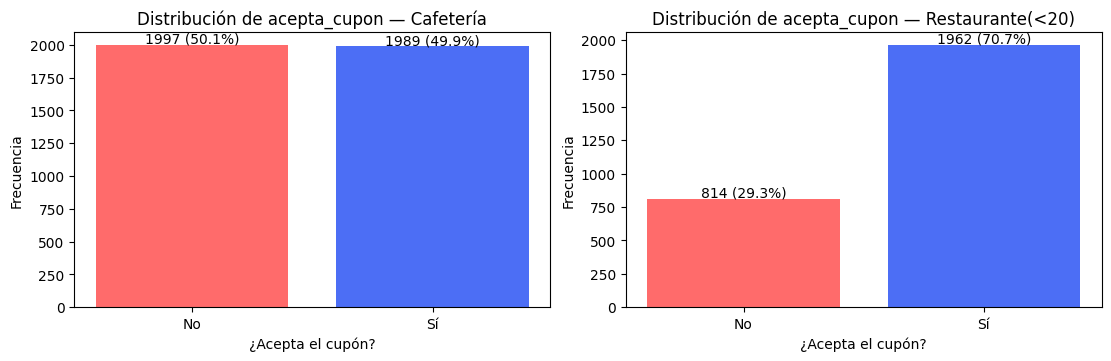

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), constrained_layout=True)
for ax, (c, df_c) in zip(axes, subconjuntos.items()):
    conteo = df_c['acepta_cupon'].value_counts().reindex(['No', 'Sí'])
    ax.bar(conteo.index, conteo.values, color=['#FF6B6B', '#4C6EF5'])
    for i, v in enumerate(conteo.values):
        ax.text(i, v + 15, f'{v} ({v/len(df_c)*100:.1f}%)', ha='center')
    ax.set(title=f'Distribución de acepta_cupon — {c}', xlabel='¿Acepta el cupón?', ylabel='Frecuencia')
plt.show()

#### Relación de algunas variables con la aceptación

Para orientar el modelado revisamos la **tasa de aceptación** (porcentaje de "Sí") según algunas variables de contexto y de hábitos de consumo.

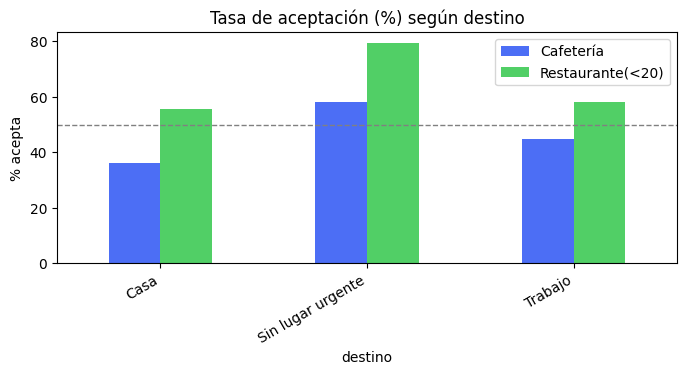

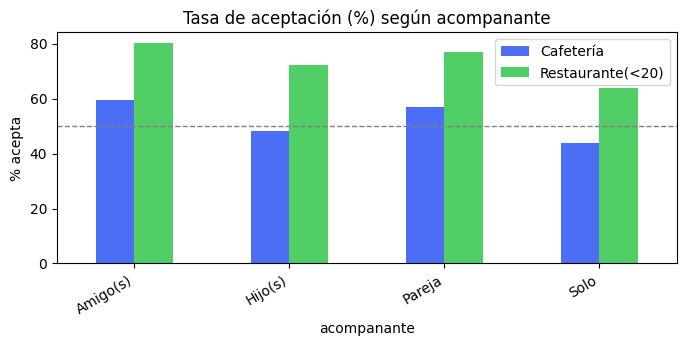

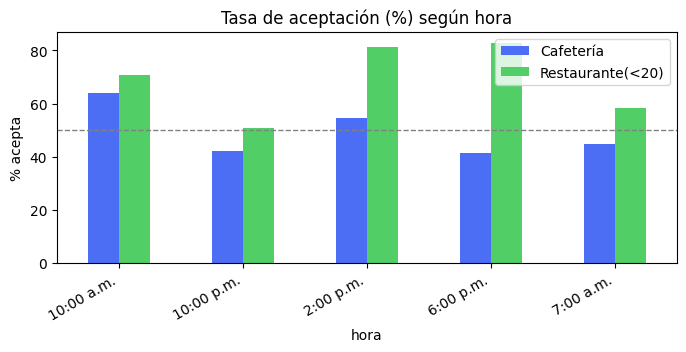

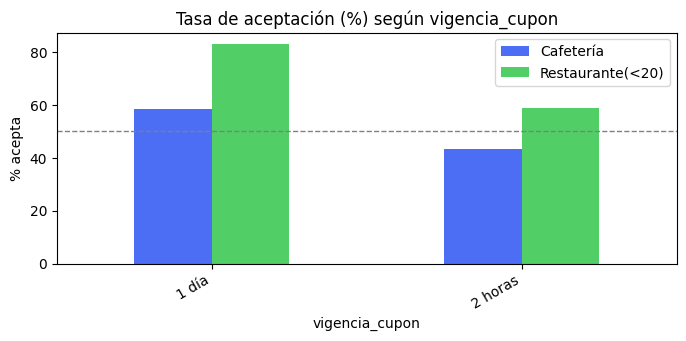

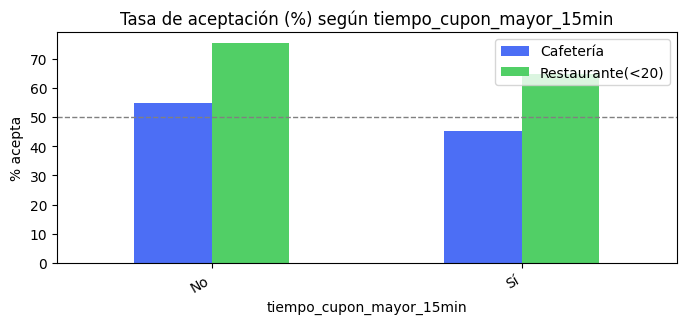

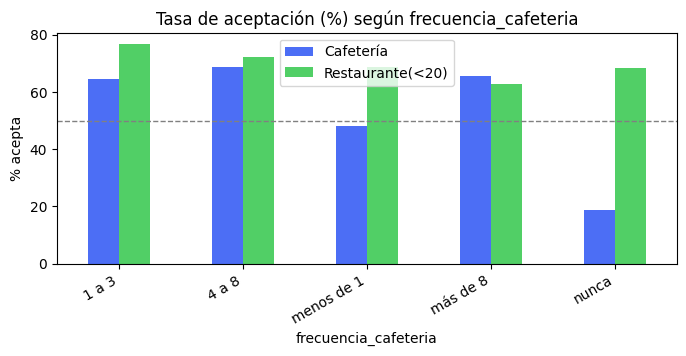

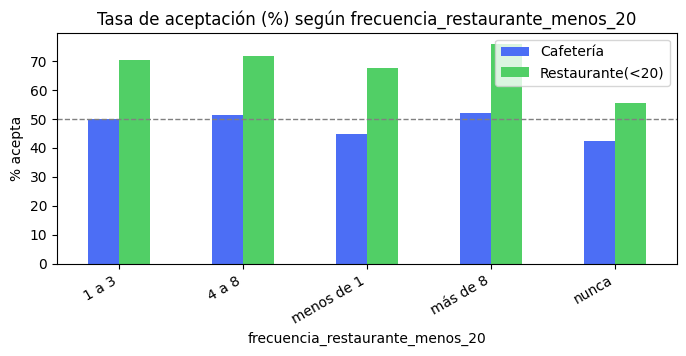

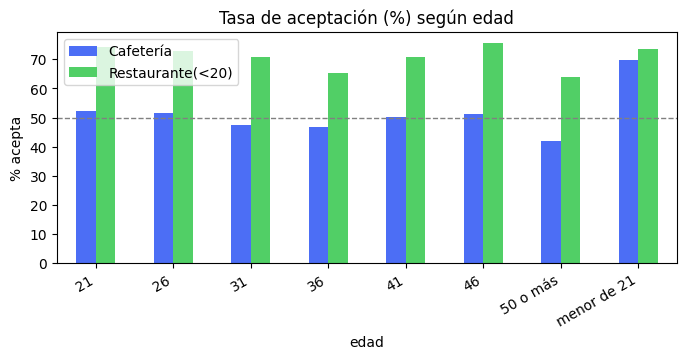

In [30]:
variables_explorar = ['destino', 'acompanante', 'hora', 'vigencia_cupon', 'tiempo_cupon_mayor_15min',
                      'frecuencia_cafeteria', 'frecuencia_restaurante_menos_20', 'edad']

for var in variables_explorar:
    tasas = pd.DataFrame({
        c: df_c.groupby(var)['acepta_cupon'].apply(lambda s: (s == 'Sí').mean() * 100)
        for c, df_c in subconjuntos.items()
    })
    tasas.plot(kind='bar', figsize=(8, 3), color=['#4C6EF5', '#51CF66'])
    plt.title(f'Tasa de aceptación (%) según {var}')
    plt.ylabel('% acepta')
    plt.xticks(rotation=30, ha='right')
    plt.axhline(50, color='gray', linestyle='--', lw=1)
    plt.show()

### Analisis de calidad y caracteristicas relevantes

A partir de la exploración se identifican los siguientes aspectos:

**Completitud**
- vehiculo tiene más del 99% de valores faltantes (solo 108 registros de 12.664 tienen valor). No es posible imputarla de forma confiable y no aporta información, por lo que **se elimina**.
- Las cinco variables de frecuencia (frecuencia_bar, frecuencia_cafeteria, frecuencia_comida_para_llevar, frecuencia_restaurante_menos_20, frecuencia_restaurante_20_a_50) tienen entre 0,8% y 1,8% de faltantes. Son pocos, así que se **imputan dentro del pipeline**.

**Unicidad**
- Hay filas exactamente duplicadas (74 en el total; 7 en cada subconjunto). Se eliminan antes de particionar, para que una misma observación no quede en train y en test al mismo tiempo.

**Consistencia y validez**
- Las categorías de todas las variables coinciden con el diccionario; no hay errores de escritura ni valores fuera de rango.
- Las relaciones entre tiempo_cupon_mayor_15min y tiempo_cupon_mayor_25min son coherentes (no hay casos a más de 25 min y a menos de 15 min).

**Variables redundantes o sin información**
- tiempo_cupon_mayor_5min vale "Sí" en el 100% de los registros: no tiene variabilidad y **se elimina**.
- direccion_opuesta es exactamente el complemento de misma_direccion: es redundante y **se elimina** (se conserva misma_direccion).
- cupon es constante dentro de cada subconjunto, por lo que **se elimina** al modelar.
- temperatura está muy asociada a clima (Lluvioso → 55, Nevado → 30), pero cuando está soleado puede tomar los tres valores, así que sí agrega algo de información. Se conserva.

**Variable objetivo**
- **Cafetería** (3.986 registros) está prácticamente balanceada: ~50% Sí / ~50% No.
- **Restaurante(<20)** (2.776 registros) está desbalanceada: ~71% Sí / ~29% No. En este caso la clase minoritaria es **"No"** (rechazar el cupón). Por eso tiene sentido evaluar técnicas de balanceo en este subconjunto.

**Primeras señales**: la aceptación varía bastante según el destino ("Sin lugar urgente" acepta más), el acompañante, la distancia (más de 15 min reduce la aceptación) y, sobre todo, la frecuencia con la que el conductor visita ese tipo de establecimiento.

## Limpieza y preparación de los datos

Las decisiones de limpieza que **no aprenden nada de los datos** (eliminar duplicados, binarizar la variable objetivo) se hacen antes de la partición. Las que **sí aprenden de los datos** (imputación, escalado, codificación) se incluyen en el pipeline, para que se ajusten solo con el conjunto de entrenamiento.

Primero binarizamos la variable objetivo: 1 = Sí acepta, 0 = No acepta.

In [31]:
for c in cupones:
    df_c = subconjuntos[c]
    df_c = df_c.drop_duplicates().reset_index(drop=True)
    df_c['acepta_cupon_bin'] = np.where(df_c['acepta_cupon'] == 'Sí', 1, 0)
    subconjuntos[c] = df_c
    print(f'{c}: {len(df_c)} registros después de eliminar duplicados')
    print(df_c['acepta_cupon_bin'].value_counts().to_dict(), '\n')

Cafetería: 3979 registros después de eliminar duplicados
{0: 1996, 1: 1983} 

Restaurante(<20): 2769 registros después de eliminar duplicados
{1: 1959, 0: 810} 



### Partición de los datos

Usamos 80% para entrenamiento y 20% para prueba, con stratify=y para mantener la proporción de clases en ambos conjuntos. La partición se hace por separado para cada tipo de cupón.

In [32]:
particiones = {}
for c in cupones:
    X = subconjuntos[c].drop(columns=['acepta_cupon', 'acepta_cupon_bin'])
    y = subconjuntos[c]['acepta_cupon_bin']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    particiones[c] = (X_train, X_test, y_train, y_test)
    print(f'{c}: train={X_train.shape}, test={X_test.shape}, '
          f'% Sí train={y_train.mean()*100:.1f}%, % Sí test={y_test.mean()*100:.1f}%')

Cafetería: train=(3183, 25), test=(796, 25), % Sí train=49.8%, % Sí test=49.9%
Restaurante(<20): train=(2215, 25), test=(554, 25), % Sí train=70.7%, % Sí test=70.8%


### Pasos del pipeline

**Eliminación de columnas.** Como en la práctica de regresión logística, se usa un FunctionTransformer para eliminar las columnas descartadas en la exploración. Así el pipeline puede recibir los datos con su estructura original (por ejemplo, el archivo de prueba).

In [33]:
cols_to_drop = ['vehiculo', 'tiempo_cupon_mayor_5min', 'direccion_opuesta', 'cupon']

def drop_columns(df):
    return df.drop(columns=cols_to_drop, errors='ignore')

dropper = FunctionTransformer(drop_columns)

**Separación por tipo de variable.** La única variable numérica es temperatura; el resto son categóricas (nominales u ordinales).

In [34]:
numericas_features = ['temperatura']
categoricas_features = ['destino', 'acompanante', 'clima', 'hora', 'vigencia_cupon', 'genero', 'edad',
                        'estado_civil', 'tiene_hijos', 'educacion', 'ocupacion', 'ingreso',
                        'frecuencia_bar', 'frecuencia_cafeteria', 'frecuencia_comida_para_llevar',
                        'frecuencia_restaurante_menos_20', 'frecuencia_restaurante_20_a_50',
                        'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min', 'misma_direccion']

**Transformaciones para regresión logística.**
- Numéricas: SimpleImputer(strategy='median') + StandardScaler(). La estandarización es importante porque la regularización penaliza los coeficientes y estos deben estar en escalas comparables.
- Categóricas: los faltantes se representan explícitamente como la categoría Sin información (el hecho de no reportar la frecuencia puede ser informativo en sí mismo) y luego se aplica OneHotEncoder(drop='first') para dejar una categoría de referencia y facilitar la interpretación de los coeficientes. handle_unknown='ignore' evita errores si aparece una categoría no vista en entrenamiento.

In [35]:
numerica_transformer_rl = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorica_transformer_rl = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='constant', fill_value='Sin información')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

preprocesador_rl = ColumnTransformer(transformers=[
    ('num', numerica_transformer_rl, numericas_features),
    ('cat', categorica_transformer_rl, categoricas_features)
])

**Transformaciones para árboles y Random Forest.** Como se vio en la práctica de árboles, estos modelos no necesitan escalado (las particiones dependen del orden de los valores, no de su magnitud), así que la variable numérica pasa con 'passthrough'. Para las categóricas se usa la misma imputación y OneHotEncoder(drop='if_binary').

In [36]:
categorica_transformer_arbol = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='constant', fill_value='Sin información')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='if_binary'))
])

preprocesador_arbol = ColumnTransformer(transformers=[
    ('num', 'passthrough', numericas_features),
    ('cat', categorica_transformer_arbol, categoricas_features)
])

**Validación cruzada y métrica.** Usamos StratifiedKFold con 10 particiones (mantiene la proporción de clases en cada fold) y GridSearchCV con scoring='f1_macro'. Elegimos f1_macro porque promedia el F1 de las dos clases con el mismo peso: en Restaurante(<20), donde "No" es minoritaria, evita que se premie un modelo que ignore a quienes rechazan el cupón. En Cafetería, que está balanceada, f1_macro y f1 dan resultados muy parecidos, así que usamos la misma métrica para que los dos casos sean comparables.

Además, definimos dos funciones auxiliares para resumir los resultados de la búsqueda y calcular las métricas de evaluación.

In [37]:
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

def resumen_grid(grid, params, top=10):
    resultados = pd.DataFrame(grid.cv_results_)
    cols = ['param_' + p for p in params] + ['mean_test_score', 'std_test_score', 'rank_test_score']
    return resultados[cols].sort_values(by='rank_test_score').head(top)

def metricas_modelo(y_true, y_pred):
    return {
        'Exactitud': accuracy_score(y_true, y_pred),
        'Precisión (Sí)': precision_score(y_true, y_pred, pos_label=1),
        'Recall (Sí)': recall_score(y_true, y_pred, pos_label=1),
        'F1 (Sí)': f1_score(y_true, y_pred, pos_label=1),
        'Precisión (No)': precision_score(y_true, y_pred, pos_label=0),
        'Recall (No)': recall_score(y_true, y_pred, pos_label=0),
        'F1 (No)': f1_score(y_true, y_pred, pos_label=0),
        'F1-macro': f1_score(y_true, y_pred, average='macro'),
    }

def tabla_train_test(modelo, X_train, y_train, X_test, y_test):
    m_train = metricas_modelo(y_train, modelo.predict(X_train))
    m_test = metricas_modelo(y_test, modelo.predict(X_test))
    texto = '|Métrica|Train|Test|\n|-------|-----|----|\n'
    for k in ['Exactitud', 'Precisión (Sí)', 'Recall (Sí)', 'F1 (Sí)', 'F1-macro']:
        texto += f'|{k}|{m_train[k]:.2%}|{m_test[k]:.2%}|\n'
    display(Markdown(texto))

# Diccionario donde se guardan los mejores modelos de cada algoritmo y cupón
modelos = {}

## Modelos de regresión logística

Pipeline: dropper → preprocesador_rl → LogisticRegression.

En la búsqueda exploramos el **tipo de regularización** (penalty), el **solver** y la fuerza de la regularización C (recordando que valores pequeños de C implican mayor regularización). Como no todos los solvers admiten todas las penalizaciones, el espacio se define con dos diccionarios de combinaciones válidas, igual que en la práctica:
- L2: newton-cg, lbfgs, liblinear, saga.
- L1: liblinear, saga.

In [38]:
pipeline_rl = Pipeline(steps=[
    ('dropper', dropper),
    ('preprocesador', preprocesador_rl),
    ('modelo', LogisticRegression(max_iter=2000, random_state=42))
])

param_grid_rl = [
    {
        'modelo__penalty': ['l2'],
        'modelo__solver': ['newton-cg', 'lbfgs', 'liblinear', 'saga'],
        'modelo__C': [0.01, 0.1, 0.5, 1, 5]
    },
    {
        'modelo__penalty': ['l1'],
        'modelo__solver': ['liblinear', 'saga'],
        'modelo__C': [0.01, 0.1, 0.5, 1, 5]
    }
]

### Regresion logistica - Cafeteria

In [39]:
X_train, X_test, y_train, y_test = particiones['Cafetería']

grid_rl_caf = GridSearchCV(estimator=pipeline_rl, param_grid=param_grid_rl, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_rl_caf.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid_rl_caf.best_params_)
print(f'Mejor puntaje medio en CV (f1_macro): {grid_rl_caf.best_score_:.4f}')

Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}
Mejor puntaje medio en CV (f1_macro): 0.7195


C:\Users\Esteban\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [40]:
resumen_grid(grid_rl_caf, ['modelo__penalty', 'modelo__solver', 'modelo__C'])

,param_modelo__penalty,param_modelo__solver,param_modelo__C,mean_test_score,std_test_score,rank_test_score
6,l2,liblinear,0.1,0.719527,0.022937,1
24,l1,liblinear,0.5,0.719184,0.023187,2
25,l1,saga,0.5,0.718530,0.024538,3
22,l1,liblinear,0.1,0.718447,0.020835,4
5,l2,lbfgs,0.1,0.718311,0.023917,5
4,l2,newton-cg,0.1,0.717985,0.024300,6
26,l1,liblinear,1.0,0.717953,0.017301,7
7,l2,saga,0.1,0.717317,0.022308,8
27,l1,saga,1.0,0.717026,0.016658,9
10,l2,liblinear,0.5,0.716378,0.017455,10


In [41]:
modelos[('Regresión logística', 'Cafetería')] = grid_rl_caf.best_estimator_
tabla_train_test(grid_rl_caf.best_estimator_, X_train, y_train, X_test, y_test)

|Métrica|Train|Test|
|-------|-----|----|
|Exactitud|73.23%|70.48%|
|Precisión (Sí)|72.41%|69.19%|
|Recall (Sí)|74.78%|73.55%|
|F1 (Sí)|73.57%|71.31%|
|F1-macro|73.23%|70.45%|


### Regresion logistica - Resaturante(<20)

In [42]:
X_train, X_test, y_train, y_test = particiones['Restaurante(<20)']

grid_rl_rest = GridSearchCV(estimator=pipeline_rl, param_grid=param_grid_rl, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_rl_rest.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid_rl_rest.best_params_)
print(f'Mejor puntaje medio en CV (f1_macro): {grid_rl_rest.best_score_:.4f}')

Mejores hiperparámetros: {'modelo__C': 0.1, 'modelo__penalty': 'l2', 'modelo__solver': 'newton-cg'}
Mejor puntaje medio en CV (f1_macro): 0.6683


C:\Users\Esteban\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [43]:
resumen_grid(grid_rl_rest, ['modelo__penalty', 'modelo__solver', 'modelo__C'])

,param_modelo__penalty,param_modelo__solver,param_modelo__C,mean_test_score,std_test_score,rank_test_score
5,l2,lbfgs,0.1,0.668334,0.027120,1
4,l2,newton-cg,0.1,0.668334,0.027120,1
9,l2,lbfgs,0.5,0.667860,0.024375,3
8,l2,newton-cg,0.5,0.667860,0.024375,3
19,l2,saga,5.0,0.667262,0.024368,5
7,l2,saga,0.1,0.667084,0.025566,6
11,l2,saga,0.5,0.666542,0.025609,7
25,l1,saga,0.5,0.666445,0.029114,8
24,l1,liblinear,0.5,0.666371,0.030737,9
6,l2,liblinear,0.1,0.666262,0.025512,10


In [44]:
modelos[('Regresión logística', 'Restaurante(<20)')] = grid_rl_rest.best_estimator_
tabla_train_test(grid_rl_rest.best_estimator_, X_train, y_train, X_test, y_test)

|Métrica|Train|Test|
|-------|-----|----|
|Exactitud|77.34%|77.08%|
|Precisión (Sí)|78.80%|78.62%|
|Recall (Sí)|92.98%|92.86%|
|F1 (Sí)|85.30%|85.15%|
|F1-macro|67.90%|67.47%|


En ambos cupones las métricas de entrenamiento y prueba son cercanas, lo que indica que la regresión logística regularizada no está sobreajustando. La comparación detallada en test se hace mas adelante

## Modelos de arboles de decision

Pipeline: dropper → preprocesador_arbol → DecisionTreeClassifier.

Exploramos el **criterio de división** (gini, entropy, log_loss), la **profundidad máxima** y el **número mínimo de muestras por hoja**. Los dos últimos controlan la complejidad del árbol: árboles muy profundos u hojas con muy pocas muestras tienden a memorizar el entrenamiento (sobreajuste).

In [45]:
pipeline_arbol = Pipeline(steps=[
    ('dropper', dropper),
    ('preprocesador', preprocesador_arbol),
    ('modelo', DecisionTreeClassifier(random_state=42))
])

param_grid_arbol = {
    'modelo__criterion': ['gini', 'entropy', 'log_loss'],
    'modelo__max_depth': [3, 5, 7, 10, 15, None],
    'modelo__min_samples_leaf': [1, 5, 10, 20, 40]
}

### Arbol de decision - cafeteria

In [46]:
X_train, X_test, y_train, y_test = particiones['Cafetería']

grid_arbol_caf = GridSearchCV(estimator=pipeline_arbol, param_grid=param_grid_arbol, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_arbol_caf.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid_arbol_caf.best_params_)
print(f'Mejor puntaje medio en CV (f1_macro): {grid_arbol_caf.best_score_:.4f}')

C:\Users\Esteban\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Mejores hiperparámetros: {'modelo__criterion': 'entropy', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 10}
Mejor puntaje medio en CV (f1_macro): 0.7124


In [47]:
resumen_grid(grid_arbol_caf, ['modelo__criterion', 'modelo__max_depth', 'modelo__min_samples_leaf'])

,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
37,entropy,5,10,0.712365,0.023086,1
67,log_loss,5,10,0.712365,0.023086,1
65,log_loss,5,1,0.711752,0.022352,3
35,entropy,5,1,0.711752,0.022352,3
36,entropy,5,5,0.710820,0.021791,5
66,log_loss,5,5,0.710820,0.021791,5
7,gini,5,10,0.707331,0.022228,7
38,entropy,5,20,0.706949,0.025224,8
68,log_loss,5,20,0.706949,0.025224,8
10,gini,7,1,0.706668,0.026116,10


In [48]:
modelos[('Árbol de decisión', 'Cafetería')] = grid_arbol_caf.best_estimator_
tabla_train_test(grid_arbol_caf.best_estimator_, X_train, y_train, X_test, y_test)

|Métrica|Train|Test|
|-------|-----|----|
|Exactitud|72.89%|68.97%|
|Precisión (Sí)|74.02%|69.33%|
|Recall (Sí)|70.24%|67.76%|
|F1 (Sí)|72.08%|68.54%|
|F1-macro|72.86%|68.96%|


### 6.2 Arbol de decisión — Restaurante(<20)

In [49]:
X_train, X_test, y_train, y_test = particiones['Restaurante(<20)']

grid_arbol_rest = GridSearchCV(estimator=pipeline_arbol, param_grid=param_grid_arbol, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_arbol_rest.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid_arbol_rest.best_params_)
print(f'Mejor puntaje medio en CV (f1_macro): {grid_arbol_rest.best_score_:.4f}')

Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 20}
Mejor puntaje medio en CV (f1_macro): 0.6716


In [50]:
resumen_grid(grid_arbol_rest, ['modelo__criterion', 'modelo__max_depth', 'modelo__min_samples_leaf'])

,param_modelo__criterion,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
8,gini,5,20,0.671583,0.033629,1
6,gini,5,5,0.670516,0.027837,2
35,entropy,5,1,0.670463,0.020388,3
65,log_loss,5,1,0.670463,0.020388,3
5,gini,5,1,0.668816,0.031886,5
7,gini,5,10,0.666442,0.037778,6
67,log_loss,5,10,0.665736,0.023196,7
37,entropy,5,10,0.665736,0.023196,7
36,entropy,5,5,0.664743,0.020517,9
66,log_loss,5,5,0.664743,0.020517,9


In [51]:
modelos[('Árbol de decisión', 'Restaurante(<20)')] = grid_arbol_rest.best_estimator_
tabla_train_test(grid_arbol_rest.best_estimator_, X_train, y_train, X_test, y_test)

|Métrica|Train|Test|
|-------|-----|----|
|Exactitud|77.25%|75.09%|
|Precisión (Sí)|79.71%|77.61%|
|Recall (Sí)|91.00%|91.07%|
|F1 (Sí)|84.98%|83.80%|
|F1-macro|69.03%|64.95%|


La búsqueda favorece árboles con profundidad limitada y/o un mínimo de muestras por hoja mayor que 1, lo que confirma que un árbol sin restricciones sobreajustaría. Aun así, la diferencia entre train y test es mayor que en la regresión logística, algo típico de los árboles individuales (alta varianza).

## Modelos de Random Forest

Random Forest es un *ensemble* de tipo *bagging*: entrena muchos árboles sobre muestras bootstrap de los datos y, en cada partición, considera solo un subconjunto aleatorio de variables (max_features='sqrt' por defecto). Al promediar árboles poco correlacionados, se reduce la varianza de un árbol individual.

Pipeline: dropper → preprocesador_arbol → RandomForestClassifier.

Exploramos el **número de árboles**, la **profundidad máxima** y el **mínimo de muestras por hoja**.

In [54]:
pipeline_rf = Pipeline(steps=[
    ('dropper', dropper),
    ('preprocesador', preprocesador_arbol),
    ('modelo', RandomForestClassifier(random_state=42, n_jobs=-1))
])

param_grid_rf = {
    'modelo__n_estimators': [100, 200],
    'modelo__max_depth': [10, 20, None],
    'modelo__min_samples_leaf': [1, 3, 5]
}

### Random Forest - Cafeteria

In [55]:
X_train, X_test, y_train, y_test = particiones['Cafetería']

grid_rf_caf = GridSearchCV(estimator=pipeline_rf, param_grid=param_grid_rf, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_rf_caf.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid_rf_caf.best_params_)
print(f'Mejor puntaje medio en CV (f1_macro): {grid_rf_caf.best_score_:.4f}')

Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
Mejor puntaje medio en CV (f1_macro): 0.7661


In [56]:
resumen_grid(grid_rf_caf, ['modelo__n_estimators', 'modelo__max_depth', 'modelo__min_samples_leaf'])

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
13,200,None,1,0.766128,0.014710,1
6,100,20,1,0.764554,0.016211,2
7,200,20,1,0.763244,0.016712,3
12,100,None,1,0.761987,0.026617,4
8,100,20,3,0.754958,0.014248,5
15,200,None,3,0.754628,0.014727,6
14,100,None,3,0.751823,0.013689,7
9,200,20,3,0.751457,0.013456,8
0,100,10,1,0.749343,0.017261,9
1,200,10,1,0.745551,0.013872,10


In [57]:
modelos[('Random Forest', 'Cafetería')] = grid_rf_caf.best_estimator_
tabla_train_test(grid_rf_caf.best_estimator_, X_train, y_train, X_test, y_test)

|Métrica|Train|Test|
|-------|-----|----|
|Exactitud|99.91%|78.02%|
|Precisión (Sí)|100.00%|77.07%|
|Recall (Sí)|99.81%|79.60%|
|F1 (Sí)|99.91%|78.31%|
|F1-macro|99.91%|78.01%|


### Random Forest - Restaurante (<20)

In [58]:
X_train, X_test, y_train, y_test = particiones['Restaurante(<20)']

grid_rf_rest = GridSearchCV(estimator=pipeline_rf, param_grid=param_grid_rf, cv=kfold, scoring='f1_macro', n_jobs=-1)
grid_rf_rest.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid_rf_rest.best_params_)
print(f'Mejor puntaje medio en CV (f1_macro): {grid_rf_rest.best_score_:.4f}')

Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}
Mejor puntaje medio en CV (f1_macro): 0.7026


In [59]:
resumen_grid(grid_rf_rest, ['modelo__n_estimators', 'modelo__max_depth', 'modelo__min_samples_leaf'])

,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_leaf,mean_test_score,std_test_score,rank_test_score
12,100,None,1,0.702561,0.029228,1
7,200,20,1,0.701518,0.027714,2
6,100,20,1,0.701150,0.029798,3
13,200,None,1,0.697845,0.026806,4
14,100,None,3,0.676902,0.026781,5
8,100,20,3,0.675463,0.023501,6
15,200,None,3,0.671220,0.023680,7
9,200,20,3,0.670303,0.024049,8
1,200,10,1,0.669029,0.024748,9
0,100,10,1,0.666463,0.023118,10


In [60]:
modelos[('Random Forest', 'Restaurante(<20)')] = grid_rf_rest.best_estimator_
tabla_train_test(grid_rf_rest.best_estimator_, X_train, y_train, X_test, y_test)

|Métrica|Train|Test|
|-------|-----|----|
|Exactitud|99.91%|77.62%|
|Precisión (Sí)|99.94%|79.39%|
|Recall (Sí)|99.94%|92.35%|
|F1 (Sí)|99.94%|85.38%|
|F1-macro|99.89%|68.84%|


El Random Forest alcanza métricas de entrenamiento muy altas (los árboles profundos casi memorizan el train), pero lo relevante es el desempeño en test, que se compara en la sección 9. La brecha train–test es esperable en un bosque con árboles profundos y no implica necesariamente un mal desempeño en datos nuevos.

## Balanceo de clases con SMOTE — Restaurante(<20)

En Restaurante(<20) la clase "No" representa ~29% de los datos. Evaluamos si SMOTE (sobremuestreo sintético de la clase minoritaria) mejora los modelos.

Como se vio en la práctica de KNN y SMOTE, **SMOTE debe aplicarse solo sobre el entrenamiento y dentro de cada fold de la validación cruzada**. Para eso usamos el Pipeline de imblearn, que aplica el remuestreo únicamente durante fit y no al predecir. SMOTE trabaja con distancias sobre variables numéricas, así que se ubica **después** del preprocesador (sobre las variables ya codificadas con one-hot).

Repetimos la búsqueda de hiperparámetros para los tres algoritmos con los mismos grids, para que la comparación con/sin SMOTE sea justa.

In [61]:
X_train, X_test, y_train, y_test = particiones['Restaurante(<20)']

pipelines_smote = {
    'Regresión logística': (ImbPipeline(steps=[
        ('dropper', dropper),
        ('preprocesador', preprocesador_rl),
        ('smote', SMOTE(random_state=42)),
        ('modelo', LogisticRegression(max_iter=2000, random_state=42))
    ]), param_grid_rl),
    'Árbol de decisión': (ImbPipeline(steps=[
        ('dropper', dropper),
        ('preprocesador', preprocesador_arbol),
        ('smote', SMOTE(random_state=42)),
        ('modelo', DecisionTreeClassifier(random_state=42))
    ]), param_grid_arbol),
    'Random Forest': (ImbPipeline(steps=[
        ('dropper', dropper),
        ('preprocesador', preprocesador_arbol),
        ('smote', SMOTE(random_state=42)),
        ('modelo', RandomForestClassifier(random_state=42, n_jobs=-1))
    ]), param_grid_rf),
}

modelos_smote = {}
for nombre, (pipe, grid_params) in pipelines_smote.items():
    grid_smote = GridSearchCV(estimator=pipe, param_grid=grid_params, cv=kfold, scoring='f1_macro', n_jobs=-1)
    grid_smote.fit(X_train, y_train)
    modelos_smote[nombre] = grid_smote.best_estimator_
    print(f'{nombre} + SMOTE')
    print('  Mejores hiperparámetros:', grid_smote.best_params_)
    print(f'  Mejor puntaje medio en CV (f1_macro): {grid_smote.best_score_:.4f}\n')

Regresión logística + SMOTE
  Mejores hiperparámetros: {'modelo__C': 0.01, 'modelo__penalty': 'l2', 'modelo__solver': 'liblinear'}
  Mejor puntaje medio en CV (f1_macro): 0.6917

Árbol de decisión + SMOTE
  Mejores hiperparámetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 1}
  Mejor puntaje medio en CV (f1_macro): 0.6629

Random Forest + SMOTE
  Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 200}
  Mejor puntaje medio en CV (f1_macro): 0.7151



Con los modelos ya seleccionados (solo con X_train), comparamos sobre el conjunto de prueba cada algoritmo con y sin SMOTE, poniendo atención al **F1-macro** y al **recall de la clase minoritaria ("No")**.

In [62]:
filas = {}
for nombre in ['Regresión logística', 'Árbol de decisión', 'Random Forest']:
    filas[f'{nombre} (sin SMOTE)'] = metricas_modelo(y_test, modelos[(nombre, 'Restaurante(<20)')].predict(X_test))
    filas[f'{nombre} + SMOTE'] = metricas_modelo(y_test, modelos_smote[nombre].predict(X_test))

comparacion_smote = pd.DataFrame(filas).T[['F1-macro', 'Recall (No)', 'Precisión (No)', 'F1 (No)',
                                           'Recall (Sí)', 'Precisión (Sí)', 'F1 (Sí)']]
display(comparacion_smote.round(3))

,F1-macro,Recall (No),Precisión (No),F1 (No),Recall (Sí),Precisión (Sí),F1 (Sí)
Regresión logística (sin SMOTE),0.675,0.389,0.692,0.498,0.929,0.786,0.851
Regresión logística + SMOTE,0.695,0.648,0.536,0.587,0.768,0.841,0.803
Árbol de decisión (sin SMOTE),0.649,0.364,0.628,0.461,0.911,0.776,0.838
Árbol de decisión + SMOTE,0.674,0.586,0.519,0.551,0.776,0.819,0.797
Random Forest (sin SMOTE),0.688,0.420,0.694,0.523,0.923,0.794,0.854
Random Forest + SMOTE,0.706,0.469,0.685,0.557,0.911,0.806,0.855


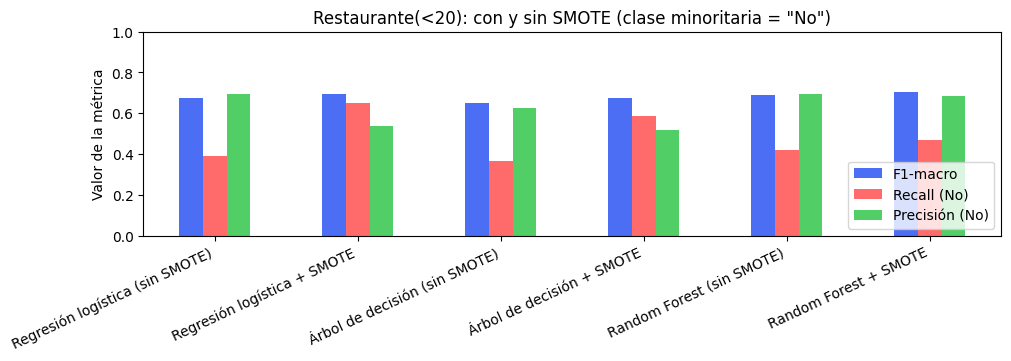

In [63]:
fig, ax = plt.subplots(figsize=(10, 3.5), constrained_layout=True)
comparacion_smote[['F1-macro', 'Recall (No)', 'Precisión (No)']].plot(kind='bar', ax=ax,
                                                                     color=['#4C6EF5', '#FF6B6B', '#51CF66'])
ax.set(ylabel='Valor de la métrica', title='Restaurante(<20): con y sin SMOTE (clase minoritaria = "No")', ylim=(0, 1))
ax.legend(loc='lower right')
plt.xticks(rotation=25, ha='right')
plt.show()

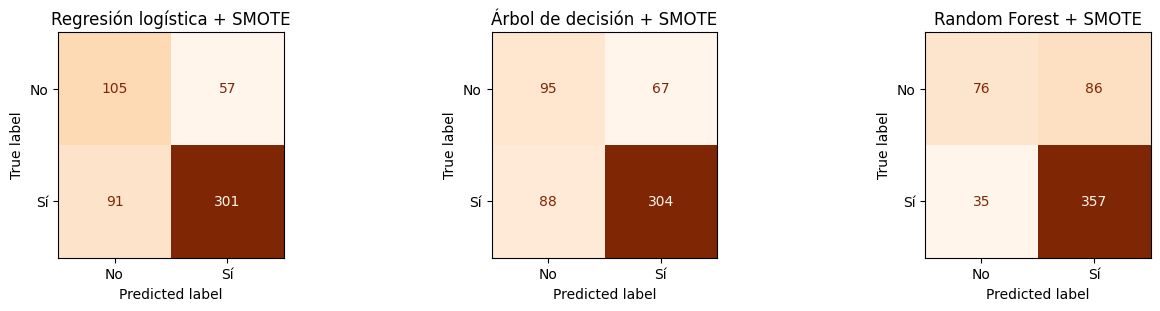

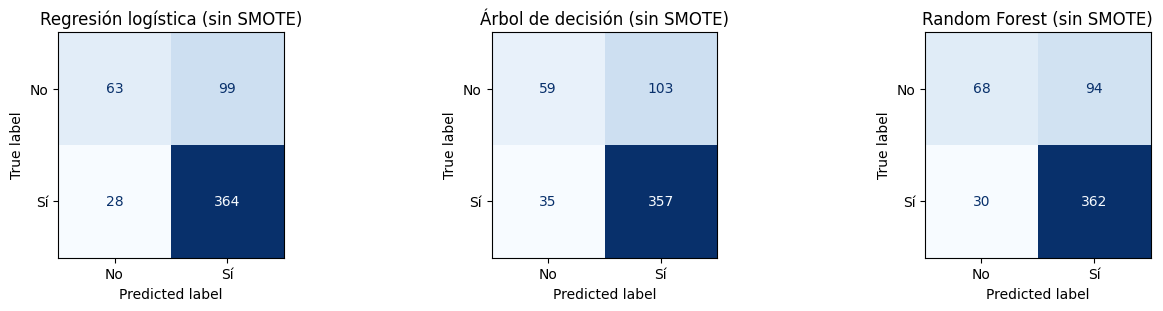

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3), constrained_layout=True)
for ax, nombre in zip(axes, ['Regresión logística', 'Árbol de decisión', 'Random Forest']):
    ConfusionMatrixDisplay.from_predictions(y_test, modelos_smote[nombre].predict(X_test),
                                            display_labels=['No', 'Sí'], cmap='Oranges', ax=ax, colorbar=False)
    ax.set_title(f'{nombre} + SMOTE')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3), constrained_layout=True)
for ax, nombre in zip(axes, ['Regresión logística', 'Árbol de decisión', 'Random Forest']):
    ConfusionMatrixDisplay.from_predictions(y_test, modelos[(nombre, 'Restaurante(<20)')].predict(X_test),
                                            display_labels=['No', 'Sí'], cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'{nombre} (sin SMOTE)')
plt.show()

### Conclusión sobre el balanceo con SMOTE

| Modelo | F1-macro sin → con SMOTE | Recall "No" sin → con SMOTE | F1 "Sí" sin → con SMOTE | F1-macro CV sin → con SMOTE |
|:--|:--:|:--:|:--:|:--:|
| Regresión logística | 0,675 → 0,657 | 0,389 → 0,593 | 0,851 → 0,779 | 0,668 → 0,687 |
| Árbol de decisión | 0,649 → 0,678 | 0,364 → 0,574 | 0,838 → 0,804 | 0,672 → 0,661 |
| Random Forest | 0,688 → 0,695 | 0,420 → 0,451 | 0,854 → 0,851 | 0,703 → 0,719 |

- **Sin balanceo, los tres modelos detectan mal la clase minoritaria**: el recall de "No" está entre 0,36 y 0,42, es decir, más de la mitad de los conductores que rechazan el cupón se clasifican como si lo fueran a aceptar. Los modelos se inclinan hacia "Sí" porque es la clase mayoritaria (~71%).
- **SMOTE mejora el recall de "No" en los tres algoritmos**, con el cambio más grande en el árbol (+21 puntos) y en la regresión logística (+20 puntos). A cambio, baja la precisión de "No" y el recall de "Sí": el modelo deja de mostrar el cupón a más personas que sí lo habrían aceptado. Es el trade-off esperado de SMOTE que vimos en la práctica.
- **En F1-macro los resultados son mixtos:** en test mejora para el árbol (+2,9 puntos) y para Random Forest (+0,7), pero empeora para la regresión logística (−1,8). En validación cruzada pasa al revés con el árbol y la regresión logística: mejora la regresión logística y empeora el árbol. Solo Random Forest mejora en ambas evaluaciones. SMOTE no es una técnica que "siempre mejora todo".
- En **Random Forest**, SMOTE da el mejor F1-macro tanto en CV (0,719) como en test (0,695) y sube el recall de "No" sin sacrificar casi nada del F1 de "Sí" (0,854 → 0,851).

**Recomendación:** sí conviene aplicar SMOTE en Restaurante(<20), junto con **Random Forest**, porque mejora el equilibrio entre clases sin afectar el desempeño sobre quienes aceptan. Si para Ruta Alpes la prioridad fuera evitar notificaciones molestas (detectar a quien va a rechazar), la regresión logística con SMOTE es la opción con mayor recall de "No" (0,593), pero perdería cerca de 18 puntos de recall en "Sí", es decir, oportunidades de conversión. La elección final depende del costo relativo de cada error para el negocio.

*Limitación:* SMOTE interpola entre vecinos en el espacio one-hot, por lo que los registros sintéticos tienen valores fraccionarios (por ejemplo, 0,4 en una categoría) que no corresponden a un conductor real. Una alternativa más adecuada para datos categóricos sería SMOTENC (o SMOTEN), o usar class_weight='balanced' en los modelos.

## Tabla comparativa de modelos sobre test

Evaluamos los tres algoritmos (sin balanceo) sobre el conjunto de prueba de cada cupón con las métricas solicitadas: **precisión, recall y F1-score**. Reportamos estas métricas para la clase positiva ("Sí acepta") y también el F1-macro, que fue la métrica de selección en la validación cruzada.

In [65]:
filas = []
for (algoritmo, c), modelo in modelos.items():
    X_train, X_test, y_train, y_test = particiones[c]
    m = metricas_modelo(y_test, modelo.predict(X_test))
    filas.append({'Cupón': c, 'Algoritmo': algoritmo, **m})

tabla_comparativa = pd.DataFrame(filas).set_index(['Cupón', 'Algoritmo'])
tabla_comparativa = tabla_comparativa[['Precisión (Sí)', 'Recall (Sí)', 'F1 (Sí)', 'Recall (No)', 'F1-macro', 'Exactitud']]
display(tabla_comparativa.round(3))

,,Precisión (Sí),Recall (Sí),F1 (Sí),Recall (No),F1-macro,Exactitud
Cupón,Algoritmo,,,,,,
Cafetería,Regresión logística,0.692,0.736,0.713,0.674,0.705,0.705
Restaurante(<20),Regresión logística,0.786,0.929,0.851,0.389,0.675,0.771
Cafetería,Árbol de decisión,0.693,0.678,0.685,0.702,0.690,0.690
Restaurante(<20),Árbol de decisión,0.776,0.911,0.838,0.364,0.649,0.751
Cafetería,Random Forest,0.771,0.796,0.783,0.764,0.780,0.780
Restaurante(<20),Random Forest,0.794,0.923,0.854,0.420,0.688,0.776


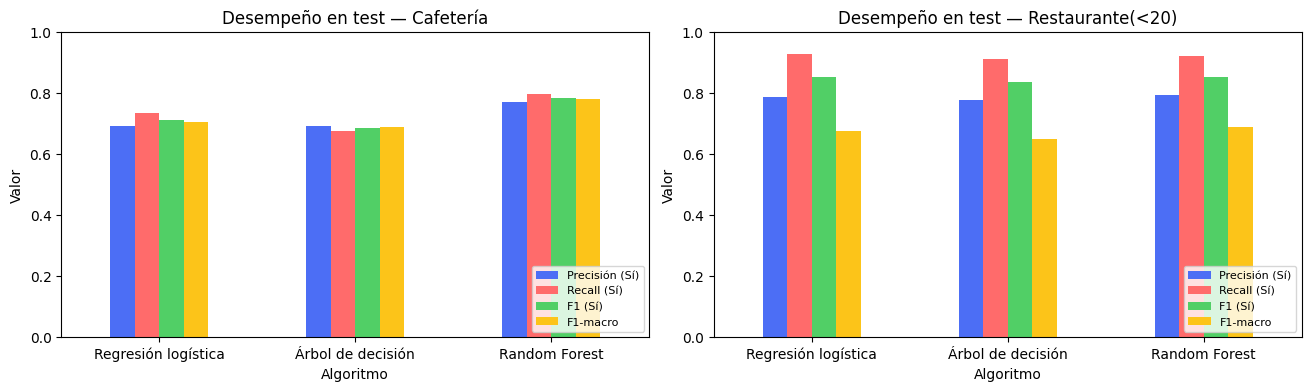

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), constrained_layout=True)
for ax, c in zip(axes, cupones):
    tabla_comparativa.loc[c][['Precisión (Sí)', 'Recall (Sí)', 'F1 (Sí)', 'F1-macro']].plot(
        kind='bar', ax=ax, color=['#4C6EF5', '#FF6B6B', '#51CF66', '#FCC419'])
    ax.set(title=f'Desempeño en test — {c}', ylabel='Valor', ylim=(0, 1))
    ax.legend(loc='lower right', fontsize=8)
    ax.tick_params(axis='x', rotation=0)
plt.show()

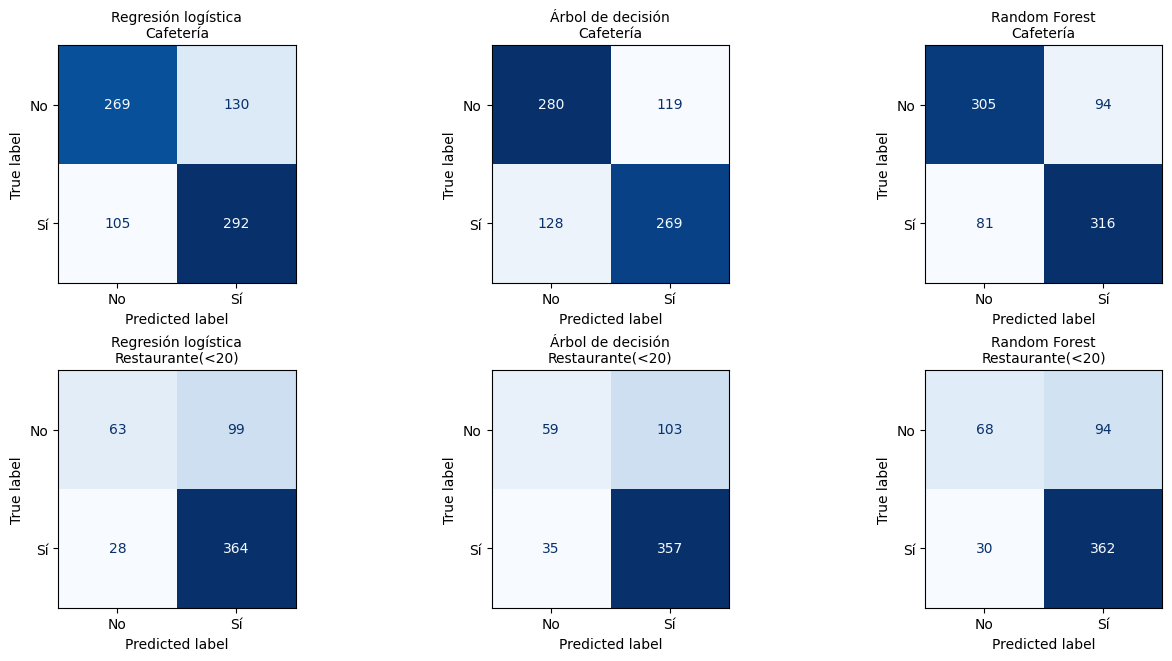

In [67]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), constrained_layout=True)
for i, c in enumerate(cupones):
    X_train, X_test, y_train, y_test = particiones[c]
    for j, algoritmo in enumerate(['Regresión logística', 'Árbol de decisión', 'Random Forest']):
        ConfusionMatrixDisplay.from_predictions(y_test, modelos[(algoritmo, c)].predict(X_test),
                                                display_labels=['No', 'Sí'], cmap='Blues',
                                                ax=axes[i, j], colorbar=False)
        axes[i, j].set_title(f'{algoritmo}\n{c}', fontsize=10)
plt.show()

### Seleccion del mejor modelo por cupon

### Selección del mejor modelo por cupón

| Cupón | Algoritmo | F1-macro CV | Precisión (Sí) test | Recall (Sí) test | F1 (Sí) test | F1-macro test |
|:--|:--|:--:|:--:|:--:|:--:|:--:|
| Cafetería | Regresión logística | 0,720 | 0,692 | 0,736 | 0,713 | 0,705 |
| Cafetería | Árbol de decisión | 0,712 | 0,693 | 0,678 | 0,685 | 0,690 |
| Cafetería | **Random Forest** | **0,766** | **0,771** | **0,796** | **0,783** | **0,780** |
| Restaurante(<20) | Regresión logística | 0,668 | 0,786 | 0,929 | 0,851 | 0,675 |
| Restaurante(<20) | Árbol de decisión | 0,672 | 0,776 | 0,911 | 0,838 | 0,649 |
| Restaurante(<20) | Random Forest | 0,703 | 0,794 | 0,923 | 0,854 | 0,688 |
| Restaurante(<20) | **Random Forest + SMOTE** | **0,719** | 0,800 | 0,908 | 0,851 | **0,695** |

**Cafetería → Random Forest.** Es el mejor en todas las métricas, tanto en validación cruzada como en test: supera a la regresión logística por unos 7 puntos de F1 y al árbol por casi 10. Su ventaja viene de que capta interacciones entre variables (por ejemplo, hábito de consumo × destino × hora) que la regresión logística, siendo lineal en los log-odds, no modela, y de que reduce la varianza de un solo árbol al promediar muchos.

**Restaurante(<20) → Random Forest + SMOTE.** Entre los modelos sin balanceo, Random Forest también es el mejor, aunque con una ventaja pequeña frente a la regresión logística en el F1 de "Sí" (0,854 vs. 0,851). Al agregar SMOTE logra el mejor F1-macro en CV y en test y el mejor recall de la clase minoritaria entre los modelos con F1 de "Sí" alto (ver sección 8).

**Sobre el sobreajuste:** los Random Forest tienen métricas de entrenamiento cercanas al 100% porque el mejor modelo usa árboles sin límite de profundidad. Aun así, la selección se hizo con validación cruzada, que mide el desempeño sobre datos no vistos, y el Random Forest también es el mejor en test. Que un bosque memorice el entrenamiento no implica que generalice mal: el promedio de árboles poco correlacionados compensa la varianza de cada árbol. La regresión logística, en cambio, tiene un rendimiento casi igual en train y test, pero más bajo: es más estable, pero tiene más sesgo.

## Variables mas relevantes

Analizamos la relevancia de las variables desde tres miradas complementarias:
1. La **importancia de variables del Random Forest** (reducción media de impureza), agregando las columnas one-hot de cada variable original para leerla a nivel de variable.
2. Los **coeficientes de la regresión logística**, que indican la dirección del efecto (hacia aceptar o rechazar).
3. Las **reglas del árbol de decisión**, que muestran combinaciones concretas de condiciones.

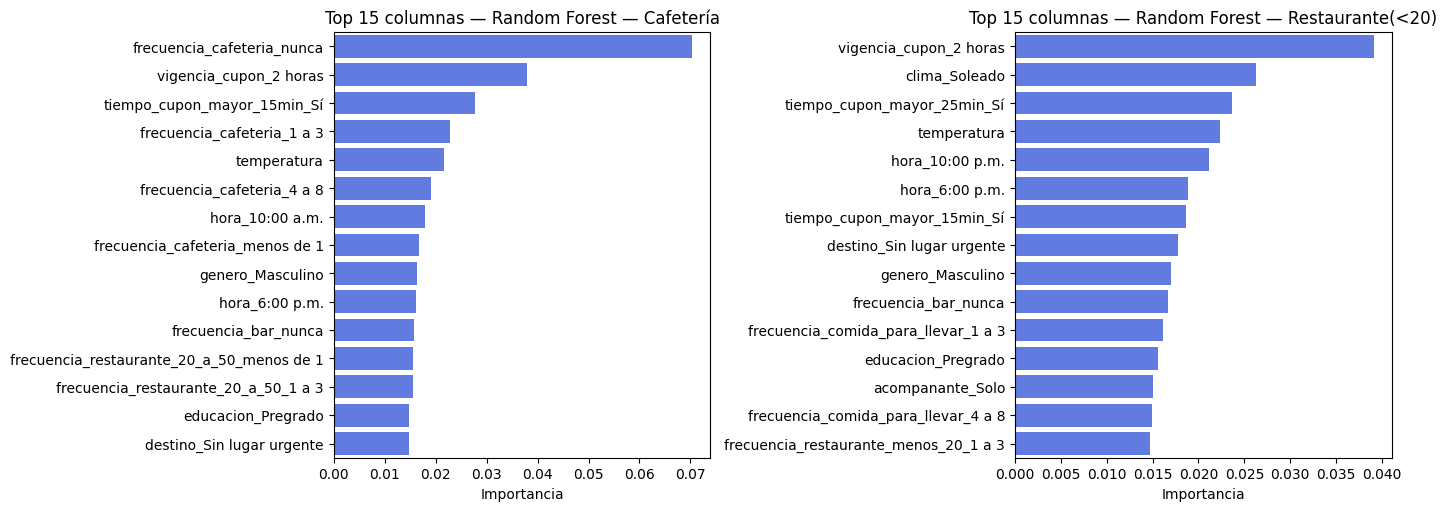

In [68]:
def nombres_features(modelo):
    preprocesador_fit = modelo.named_steps['preprocesador']
    nombres = preprocesador_fit.get_feature_names_out()
    return [n.split('__')[-1] for n in nombres]

def variable_original(nombre_dummy):
    for var in sorted(numericas_features + categoricas_features, key=len, reverse=True):
        if nombre_dummy == var or nombre_dummy.startswith(var + '_'):
            return var
    return nombre_dummy

importancias = {}
for c in cupones:
    rf_model = modelos[('Random Forest', c)]
    imp = pd.Series(rf_model.named_steps['modelo'].feature_importances_, index=nombres_features(rf_model))
    importancias[c] = imp

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, c in zip(axes, cupones):
    top = importancias[c].sort_values(ascending=False).head(15)
    sns.barplot(x=top.values, y=top.index, ax=ax, color='#4C6EF5')
    ax.set(title=f'Top 15 columnas — Random Forest — {c}', xlabel='Importancia', ylabel='')
plt.show()

,Cafetería,Restaurante(<20)
frecuencia_cafeteria,0.144,0.065
ocupacion,0.111,0.113
ingreso,0.084,0.089
edad,0.071,0.071
hora,0.058,0.072
educacion,0.055,0.058
frecuencia_bar,0.053,0.057
frecuencia_restaurante_20_a_50,0.052,0.049
frecuencia_comida_para_llevar,0.050,0.058
frecuencia_restaurante_menos_20,0.050,0.053


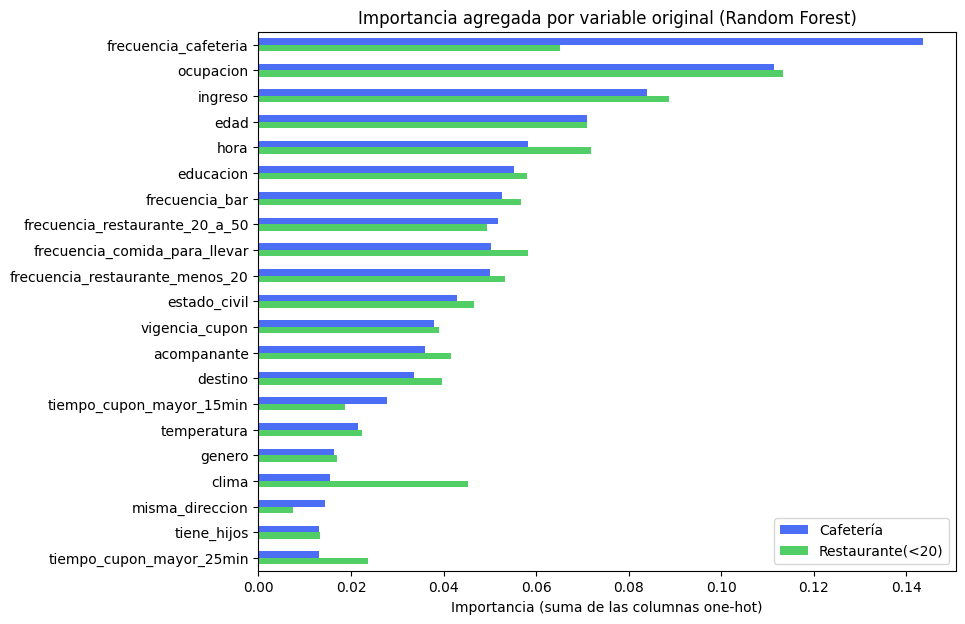

In [69]:
importancia_agregada = pd.DataFrame({
    c: importancias[c].groupby(importancias[c].index.map(variable_original)).sum()
    for c in cupones
}).sort_values('Cafetería', ascending=False)

display(importancia_agregada.round(3))

importancia_agregada.plot(kind='barh', figsize=(9, 7), color=['#4C6EF5', '#51CF66'])
plt.gca().invert_yaxis()
plt.title('Importancia agregada por variable original (Random Forest)')
plt.xlabel('Importancia (suma de las columnas one-hot)')
plt.show()

Hay que tener en cuenta que la importancia por impureza del Random Forest tiende a favorecer variables con muchas categorías (como ocupacion), porque tienen más oportunidades de generar particiones. Por eso la complementamos con los coeficientes de la regresión logística, que además indican la **dirección** del efecto.

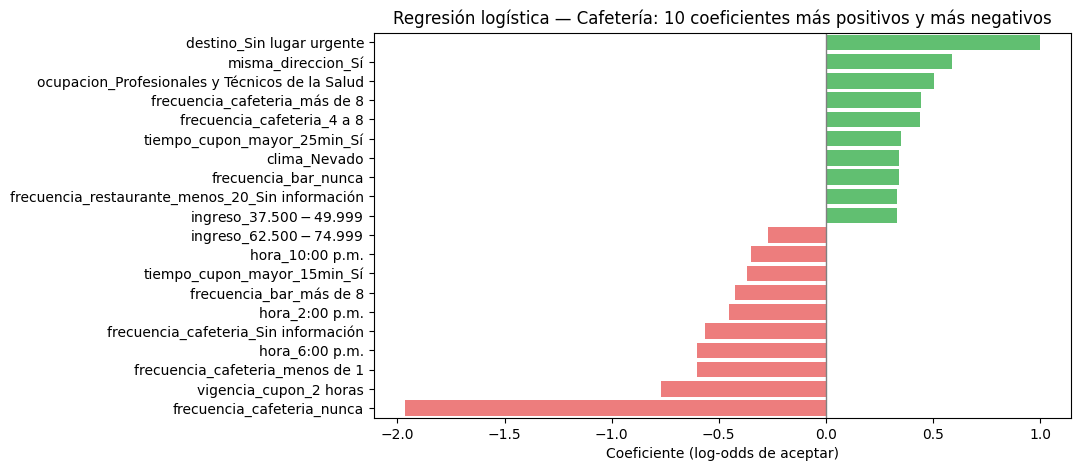

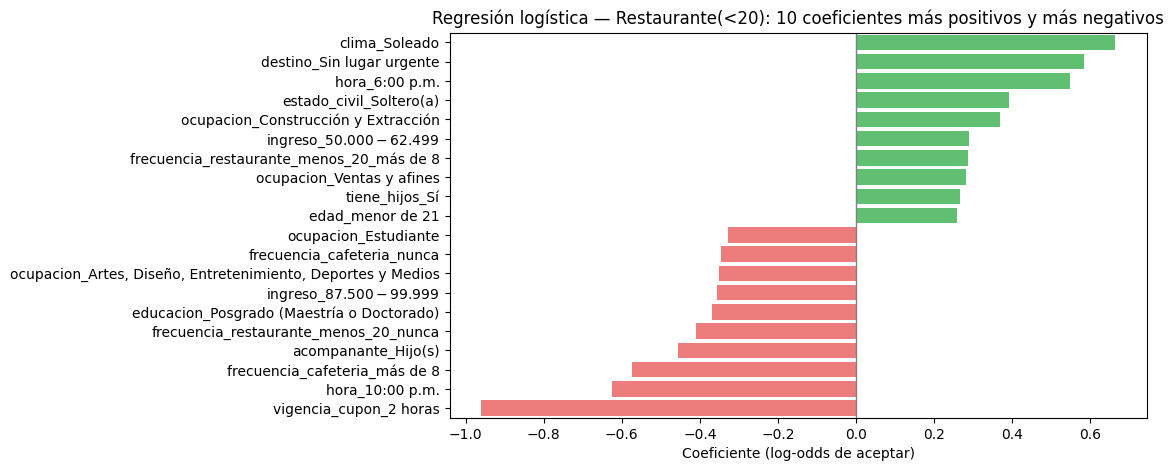

In [70]:
for c in cupones:
    rl_model = modelos[('Regresión logística', c)]
    coef_df = pd.DataFrame({'feature': nombres_features(rl_model),
                            'coef': rl_model.named_steps['modelo'].coef_[0]})
    coef_df = coef_df.sort_values('coef', ascending=False)
    top_coef = pd.concat([coef_df.head(10), coef_df.tail(10)])

    plt.figure(figsize=(9, 5))
    sns.barplot(x=top_coef['coef'], y=top_coef['feature'],
                palette=['#51CF66' if v > 0 else '#FF6B6B' for v in top_coef['coef']])
    plt.axvline(0, color='gray', lw=1)
    plt.title(f'Regresión logística — {c}: 10 coeficientes más positivos y más negativos')
    plt.xlabel('Coeficiente (log-odds de aceptar)')
    plt.ylabel('')
    plt.show()

Un coeficiente **positivo** desplaza la predicción hacia "Sí acepta" y uno **negativo** hacia "No acepta", frente a la categoría de referencia de cada variable (la que se eliminó con drop='first') y manteniendo constantes las demás variables.

#### Reglas del arbol de decision

Para que el árbol sea legible, mostramos los primeros niveles con plot_tree y las reglas completas con export_text.

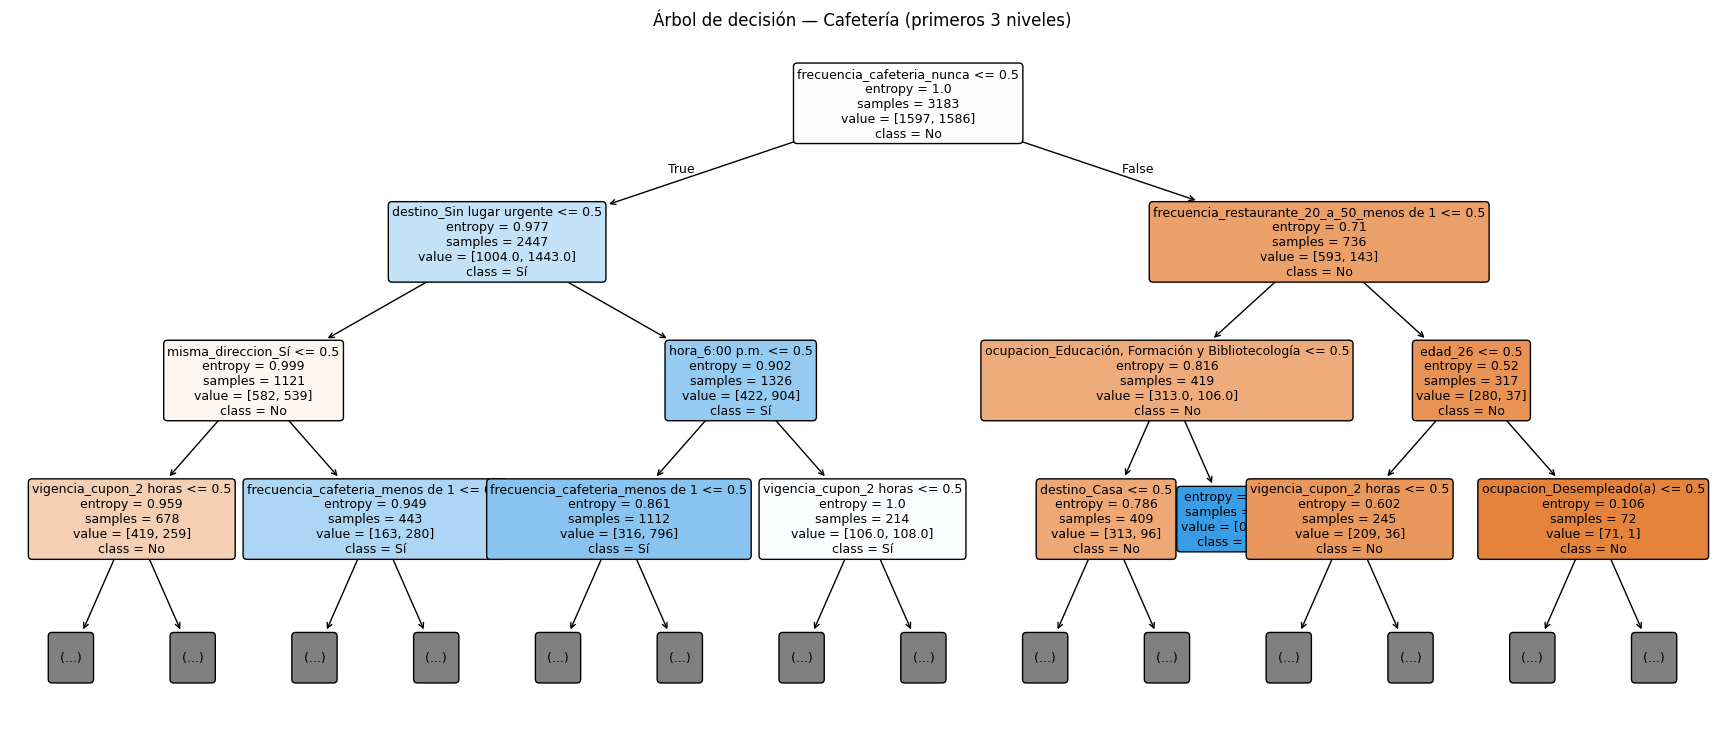

In [71]:
arbol_caf = modelos[('Árbol de decisión', 'Cafetería')]
nombres_caf = nombres_features(arbol_caf)

plt.figure(figsize=(22, 9))
plot_tree(arbol_caf.named_steps['modelo'], feature_names=nombres_caf, class_names=['No', 'Sí'],
          filled=True, rounded=True, fontsize=9, max_depth=3)
plt.title('Árbol de decisión — Cafetería (primeros 3 niveles)')
plt.show()

In [72]:
print(export_text(arbol_caf.named_steps['modelo'], feature_names=nombres_caf, max_depth=4))

|--- frecuencia_cafeteria_nunca <= 0.50
|   |--- destino_Sin lugar urgente <= 0.50
|   |   |--- misma_direccion_Sí <= 0.50
|   |   |   |--- vigencia_cupon_2 horas <= 0.50
|   |   |   |   |--- frecuencia_cafeteria_menos de 1 <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- frecuencia_cafeteria_menos de 1 >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- vigencia_cupon_2 horas >  0.50
|   |   |   |   |--- frecuencia_cafeteria_menos de 1 <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- frecuencia_cafeteria_menos de 1 >  0.50
|   |   |   |   |   |--- class: 0
|   |   |--- misma_direccion_Sí >  0.50
|   |   |   |--- frecuencia_cafeteria_menos de 1 <= 0.50
|   |   |   |   |--- hora_10:00 p.m. <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- hora_10:00 p.m. >  0.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- frecuencia_cafeteria_menos de 1 >  0.50
|   |   |   |   |--- destino_Casa <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |

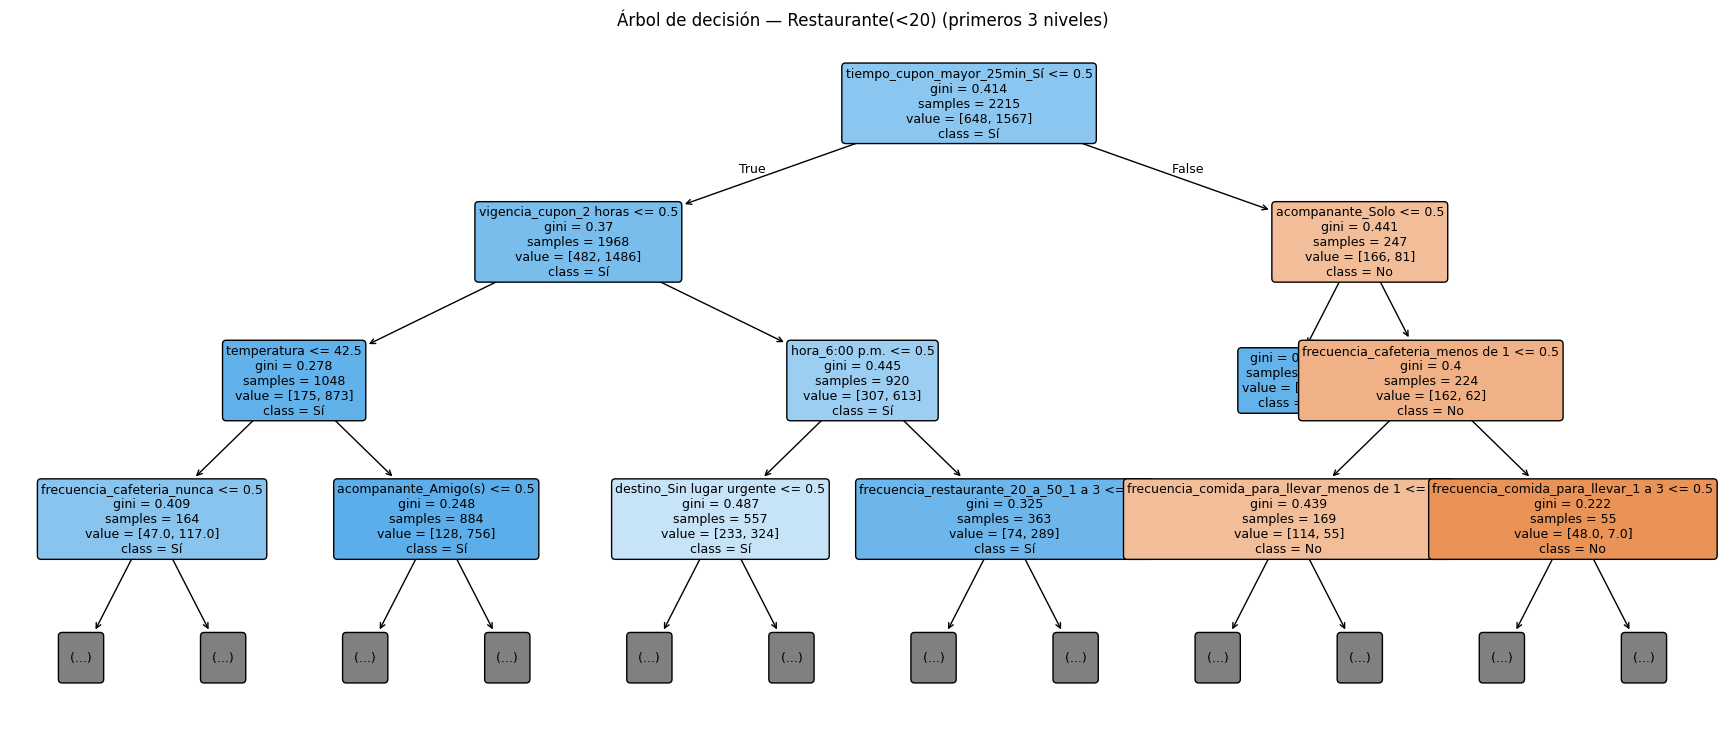

In [73]:
arbol_rest = modelos[('Árbol de decisión', 'Restaurante(<20)')]
nombres_rest = nombres_features(arbol_rest)

plt.figure(figsize=(22, 9))
plot_tree(arbol_rest.named_steps['modelo'], feature_names=nombres_rest, class_names=['No', 'Sí'],
          filled=True, rounded=True, fontsize=9, max_depth=3)
plt.title('Árbol de decisión — Restaurante(<20) (primeros 3 niveles)')
plt.show()

In [74]:
print(export_text(arbol_rest.named_steps['modelo'], feature_names=nombres_rest, max_depth=4))

|--- tiempo_cupon_mayor_25min_Sí <= 0.50
|   |--- vigencia_cupon_2 horas <= 0.50
|   |   |--- temperatura <= 42.50
|   |   |   |--- frecuencia_cafeteria_nunca <= 0.50
|   |   |   |   |--- destino_Sin lugar urgente <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- destino_Sin lugar urgente >  0.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- frecuencia_cafeteria_nunca >  0.50
|   |   |   |   |--- class: 0
|   |   |--- temperatura >  42.50
|   |   |   |--- acompanante_Amigo(s) <= 0.50
|   |   |   |   |--- hora_2:00 p.m. <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- hora_2:00 p.m. >  0.50
|   |   |   |   |   |--- class: 1
|   |   |   |--- acompanante_Amigo(s) >  0.50
|   |   |   |   |--- educacion_Pregrado <= 0.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- educacion_Pregrado >  0.50
|   |   |   |   |   |--- class: 1
|   |--- vigencia_cupon_2 horas >  0.50
|   |   |--- hora_6:00 p.m. <= 0.50
|   |   |   |--- destino_Sin lugar urgente <= 0.50


### Interpretación de las variables más relevantes

**Cafetería**
- La variable más importante es, por mucho, **frecuencia_cafeteria** (0,144 de importancia agregada en el Random Forest; es también la raíz del árbol de decisión). Quien **nunca** va a cafeterías acepta solo el ~19% de las veces, frente a ~65-69% de quienes van una vez al mes o más. Su coeficiente en la regresión logística es el más negativo (−1,96 para "nunca").
- Le siguen variables del **contexto del trayecto**: destino ("Sin lugar urgente" es el coeficiente más positivo, +1,00), hora (10:00 a.m. acepta 64%, 6:00 p.m. solo 41%), vigencia_cupon (2 horas reduce la aceptación) y la **distancia/dirección** (tiempo_cupon_mayor_15min negativo, misma_direccion positivo).
- ocupacion, ingreso y edad aparecen altas en el Random Forest, pero hay que leerlas con cuidado: tienen muchas categorías y la importancia por impureza las favorece. En la regresión logística sus coeficientes son pequeños.

**Restaurante(<20)**
- Aquí pesa más el **contexto que el hábito**: el árbol empieza por tiempo_cupon_mayor_25min (si está a más de 25 min la aceptación cae de 75% a 33%), seguido de vigencia_cupon (1 día: 83%; 2 horas: 59%) y temperatura/clima (soleado: 77%; lluvioso: 39%).
- La hora también importa: a las 2:00 p.m. y 6:00 p.m. (horas de comida) acepta más del 80%, a las 10:00 p.m. solo el 51%.
- En la regresión logística los coeficientes más positivos son clima_Soleado, destino_Sin lugar urgente y hora_6:00 p.m.; los más negativos son vigencia_cupon_2 horas, hora_10:00 p.m. y acompanante_Hijo(s).
- A diferencia de Cafetería, frecuencia_restaurante_menos_20 no domina: casi todos los conductores van a restaurantes baratos al menos de vez en cuando ("nunca" son apenas ~220 casos, menos del 2% del dataset), así que esta variable discrimina menos.

**Utilidad y limitación de esta interpretación:** las importancias y las reglas permiten explicar el modelo a Ruta Alpes en términos de negocio (por ejemplo, "no ofrecer cupones de restaurante lejos de la ruta ni con vigencia de 2 horas"). Pero describen **asociaciones**, no causas; la importancia por impureza está sesgada hacia variables con muchas categorías; las reglas de un solo árbol son inestables (pequeños cambios en los datos pueden cambiar la raíz), y la importancia de una variable se reparte entre variables correlacionadas (como clima y temperatura).

## Predicciones sobre los datos de prueba

Cargamos Lab3_datos_Prueba.xlsx, aplicamos a cada registro el mejor modelo según su tipo de cupón y exportamos el resultado a Lab3_datos_Prueba.csv, conservando las columnas originales y agregando la columna acepta_cupon con las etiquetas Sí / No. Como el pipeline incluye toda la limpieza y transformación, recibe los datos con su estructura original.

In [75]:
datos_prueba = pd.read_excel('./Data/Lab3_datos_Prueba.xlsx')
print(datos_prueba.shape)
datos_prueba['cupon'].value_counts()

(20, 25)


cupon
Cafetería           10
Restaurante(<20)    10
Name: count, dtype: int64

In [76]:
# Mejor modelo por cupón (ver justificación en las secciones 8 y 9):
# - Cafetería: Random Forest (sin balanceo, la clase ya está balanceada)
# - Restaurante(<20): Random Forest + SMOTE
mejores_modelos = {
    'Cafetería': modelos[('Random Forest', 'Cafetería')],
    'Restaurante(<20)': modelos_smote['Random Forest'],
}

In [77]:
predicciones = datos_prueba.copy()
predicciones['acepta_cupon'] = None

for c, modelo in mejores_modelos.items():
    mascara = predicciones['cupon'] == c
    pred = modelo.predict(datos_prueba.loc[mascara])
    predicciones.loc[mascara, 'acepta_cupon'] = np.where(pred == 1, 'Sí', 'No')

predicciones.to_csv('Lab3_datos_Prueba.csv', index=False, encoding='utf-8-sig')
predicciones[['cupon', 'destino', 'acompanante', 'hora', 'acepta_cupon']]

,cupon,destino,acompanante,hora,acepta_cupon
0,Cafetería,Trabajo,Solo,7:00 a.m.,Sí
1,Cafetería,Sin lugar urgente,Amigo(s),10:00 a.m.,Sí
2,Cafetería,Sin lugar urgente,Amigo(s),2:00 p.m.,Sí
3,Cafetería,Sin lugar urgente,Pareja,10:00 a.m.,Sí
4,Restaurante(<20),Sin lugar urgente,Amigo(s),6:00 p.m.,Sí
5,Restaurante(<20),Sin lugar urgente,Hijo(s),2:00 p.m.,Sí
6,Restaurante(<20),Sin lugar urgente,Solo,2:00 p.m.,No
7,Restaurante(<20),Sin lugar urgente,Amigo(s),6:00 p.m.,Sí
8,Restaurante(<20),Sin lugar urgente,Amigo(s),2:00 p.m.,Sí
9,Cafetería,Casa,Solo,6:00 p.m.,No


In [78]:
predicciones.groupby('cupon')['acepta_cupon'].value_counts()

cupon             acepta_cupon
Cafetería         Sí              7
                  No              3
Restaurante(<20)  Sí              9
                  No              1
Name: count, dtype: int64

## Persistencia de los Pipelines entrenados

In [79]:
for c, modelo in mejores_modelos.items():
    nombre_archivo = 'modelo_' + c.replace('(<20)', '_menos20').replace('í', 'i').lower() + '.joblib'
    joblib.dump(modelo, nombre_archivo)
    print('Guardado:', nombre_archivo)

Guardado: modelo_cafeteria.joblib
Guardado: modelo_restaurante_menos20.joblib


## Revisión del desempeño por subgrupos demográficos

Para apoyar el análisis de sesgos, revisamos si el mejor modelo de cada cupón se equivoca de forma parecida en distintos grupos demográficos del conjunto de prueba. Una métrica global buena puede ocultar que el modelo funciona peor para un grupo específico.

In [80]:
def desempeno_por_grupo(modelo, X_test, y_test, variable):
    filas = []
    for grupo in sorted(X_test[variable].dropna().unique()):
        mascara = X_test[variable] == grupo
        y_pred = modelo.predict(X_test[mascara])
        filas.append({variable: grupo, 'n': mascara.sum(),
                      '% Sí real': y_test[mascara].mean(),
                      '% Sí predicho': y_pred.mean(),
                      'F1-macro': f1_score(y_test[mascara], y_pred, average='macro')})
    return pd.DataFrame(filas).set_index(variable)

for c, modelo in mejores_modelos.items():
    X_train, X_test, y_train, y_test = particiones[c]
    for variable in ['genero', 'edad', 'estado_civil']:
        display(Markdown(f'**{c} — desempeño por `{variable}`**'))
        display(desempeno_por_grupo(modelo, X_test, y_test, variable).round(3))

**Cafetería — desempeño por `genero`**

,n,% Sí real,% Sí predicho,F1-macro
genero,,,,
Femenino,401,0.504,0.516,0.763
Masculino,395,0.494,0.514,0.797


**Cafetería — desempeño por `edad`**

,n,% Sí real,% Sí predicho,F1-macro
edad,,,,
21,168,0.536,0.589,0.800
26,180,0.583,0.572,0.795
31,132,0.432,0.470,0.748
36,65,0.462,0.415,0.766
41,78,0.423,0.474,0.689
46,41,0.585,0.585,0.849
50 o más,101,0.366,0.356,0.775
menor de 21,31,0.677,0.710,0.734


**Cafetería — desempeño por `estado_civil`**

...

,n,% Sí real,% Sí predicho,F1-macro
genero,,,,
Femenino,300,0.720,0.813,0.730
Masculino,254,0.693,0.783,0.679


**Restaurante(<20) — desempeño por `edad`**

,n,% Sí real,% Sí predicho,F1-macro
edad,,,,
21,95,0.800,0.874,0.711
26,111,0.748,0.793,0.682
31,87,0.770,0.828,0.553
36,65,0.569,0.677,0.754
41,47,0.660,0.851,0.626
46,28,0.857,0.964,0.451
50 o más,87,0.586,0.701,0.800
menor de 21,34,0.676,0.824,0.725


**Restaurante(<20) — desempeño por `estado_civil`**

,n,% Sí real,% Sí predicho,F1-macro
estado_civil,,,,
Casado(a),219,0.712,0.744,0.717
Divorciado(a),28,0.571,0.821,0.704
Soltero(a),198,0.677,0.828,0.675
Unión libre,99,0.798,0.879,0.702
Viudo(a),10,0.700,0.600,0.890


**Lectura de la tabla por subgrupos**

- **Cafetería:** el desempeño es relativamente parejo. Entre géneros, el F1-macro es 0,763 (Femenino) vs. 0,797 (Masculino). Por edad varía entre 0,689 (41 años) y 0,849 (46 años), y la proporción de "Sí" predicha sigue de cerca a la real en casi todos los grupos.
- **Restaurante(<20):** las diferencias son mayores. El F1-macro es 0,720 en mujeres vs. 0,666 en hombres, y por edad va de 0,451 (46 años) y 0,545 (31 años) hasta 0,785 (50 o más). Además, el modelo **sobreestima la aceptación en todos los grupos**, y más en algunos: en el grupo de 41 años la tasa real de "Sí" es 66% y la predicha 87%; en Divorciado(a), 57% vs. 82%. En la práctica, a esos grupos se les enviarían más notificaciones no deseadas.
- Parte de estas diferencias se debe al **tamaño pequeño** de algunos grupos en el test (por ejemplo, Viudo(a) tiene 4 registros en Cafetería y 10 en Restaurante), por lo que esas métricas son poco confiables. Aun así, el ejercicio muestra por qué no basta con una métrica global: antes de desplegar el modelo habría que auditarlo por subgrupos con más datos.

## Analisis de resultados

### 1. ¿Qué características del contexto de conducción o del perfil del conductor parecen estar más relacionadas con la aceptación de cada tipo de cupón?

**Cafetería.** El factor principal es el **hábito de consumo**: frecuencia_cafeteria. Quien nunca va a cafeterías casi nunca acepta (~19%), mientras que quien va al menos una vez al mes acepta ~65-69%. Después vienen las variables de contexto: ir **sin un lugar urgente** (58% vs. 36% cuando se va a casa), la **hora** (las mañanas a las 10:00 a.m. son el mejor momento, 64%; la tarde-noche el peor, ~41%), la **vigencia** (1 día > 2 horas), ir **acompañado de amigos o pareja** (~57-60% vs. 44% solo) y la **cercanía/dirección** del establecimiento.

**Restaurante(<20).** Aquí la aceptación base es alta (71%) y lo que más la reduce es el **contexto**: que el restaurante quede a **más de 25 minutos** (33% de aceptación), que el **clima** sea lluvioso o nevado (39% y 49% vs. 77% soleado), que el cupón dure solo **2 horas** y que la oferta llegue a las **10:00 p.m.** o a las **7:00 a.m.**, fuera de las horas de comida. Ir sin lugar urgente y con amigos también aumenta la aceptación.

Las variables demográficas (ocupacion, ingreso, edad) aparecen con importancia media en el Random Forest, pero su efecto en la regresión logística es pequeño y en parte se debe al sesgo de la importancia por impureza hacia variables con muchas categorías. En cambio, `genero` tiene muy poca importancia en ambos cupones (~0,016) y tasas de aceptación casi iguales entre hombres y mujeres.

### 2. ¿Existen variables que podrían ser redundantes o poco informativas?

Sí:
- **Eliminadas desde la exploración:** tiempo_cupon_mayor_5min (constante, siempre "Sí"), direccion_opuesta (complemento exacto de misma_direccion), vehiculo (>99% faltante) y cupon (constante dentro de cada subconjunto).
- **Redundancia parcial:** temperatura y clima están muy asociadas (lluvioso → 55 °F, nevado → 30 °F); tiempo_cupon_mayor_25min implica tiempo_cupon_mayor_15min. Esto reparte la importancia entre ellas y vuelve inestables los coeficientes de la regresión logística. Por ejemplo, en Cafetería tiempo_cupon_mayor_25min tiene coeficiente positivo aunque la tasa de aceptación cae cuando la distancia es mayor, porque su efecto ya está recogido en parte por la variable de 15 minutos.
- **Poco informativas:** genero, tiene_hijos y misma_direccion tienen importancias muy bajas (≤0,017) en ambos modelos. Algunas frecuencias de consumo de otros establecimientos (por ejemplo, frecuencia_restaurante_20_a_50 o frecuencia_bar para Cafetería) tienen importancia moderada en el Random Forest, pero es probable que solo estén actuando como proxy del perfil del conductor o capturando ruido.

Un siguiente paso sería volver a entrenar sin estas variables y verificar con validación cruzada si el desempeño se mantiene (un modelo más simple es más fácil de explicar y de mantener).

### 3. ¿El desempeño y el comportamiento de los modelos difieren entre Cafetería y Restaurante(<20)? Si es así, ¿a qué atribuye esa diferencia?

Sí. El mejor modelo de Cafetería alcanza un **F1-macro de 0,78** en test, mientras que el de Restaurante(<20) llega a **0,695**. Aunque en Restaurante el F1 de "Sí" es más alto (0,85), es engañoso: buena parte se explica porque la clase "Sí" es el 71% de los datos. La dificultad real está en la clase "No", cuyo recall no pasa de ~0,45 con el Random Forest.

Atribuimos la diferencia a:
1. **Desbalance de clases:** Cafetería está balanceada (50/50) y Restaurante no (71/29). Con desbalance, los modelos tienden a predecir la clase mayoritaria.
2. **Menos datos:** Restaurante tiene ~2.200 registros de entrenamiento frente a ~3.200 de Cafetería, y solo ~650 rechazos para aprender.
3. **Una señal dominante vs. señales dispersas:** en Cafetería existe una variable muy discriminante (frecuencia_cafeteria) que separa claramente a quienes aceptan de quienes no. En Restaurante, la decisión depende de una combinación de factores de contexto (distancia, clima, vigencia, hora) y la frecuencia de visita a restaurantes baratos discrimina poco, porque casi todos los conductores los frecuentan. Los rechazos parecen más heterogéneos y menos explicados por las variables disponibles.

En cuanto al comportamiento, en ambos cupones el Random Forest supera a la regresión logística y al árbol, pero la ventaja es mucho mayor en Cafetería (+7 puntos de F1) que en Restaurante (+1 a +2 puntos), lo que sugiere que en Restaurante el límite viene más de la información disponible que del algoritmo.

### 4. ¿Aplicar balanceo de clases en Restaurante(<20) mejoró el modelo?

Sí, aunque de forma moderada y con un trade-off (ver detalle en la sección 8):
- **F1-macro:** en test mejoró para Random Forest (0,688 → 0,695) y para el árbol (0,649 → 0,678), pero bajó para la regresión logística (0,675 → 0,657). En CV mejoró para Random Forest y regresión logística, pero no para el árbol. Solo Random Forest mejora de forma consistente.
- **Recall de la clase minoritaria ("No"):** mejoró en todos los casos, de forma notable en la regresión logística (0,389 → 0,593) y en el árbol (0,364 → 0,574), y de forma leve en el Random Forest (0,420 → 0,451).
- **Costo:** baja la precisión de "No" y el recall de "Sí". En la regresión logística el F1 de "Sí" cae de 0,851 a 0,779; en el Random Forest prácticamente no cambia (0,854 → 0,851).

Por eso recomendamos **Random Forest + SMOTE** como modelo final para Restaurante(<20): obtiene el mejor F1-macro en CV y test, mejora la detección de rechazos y casi no sacrifica la detección de aceptaciones. La mejora es pequeña y podría estar dentro de la variabilidad de la partición, así que vale la pena confirmarla con más datos o con técnicas más apropiadas para variables categóricas (SMOTENC, class_weight='balanced') o ajustando el umbral de decisión.

### 5. A partir de alguno de los modelos de árbol o Random Forest describa, en términos de reglas o de importancia de variables, las características que llevan a aceptar o rechazar un cupón. Incluya la utilidad y la limitación de este tipo de interpretación.

Tomando el **árbol de decisión de Cafetería** (profundidad 5), las primeras reglas son:
- **Si el conductor nunca va a cafeterías** (frecuencia_cafeteria = nunca) → la mayoría de las ramas terminan en **rechazo**. Es la primera pregunta del árbol.
- **Si sí va a cafeterías y va "sin lugar urgente"** → la mayoría de las hojas predicen **aceptación**, salvo cuando la oferta llega a las 6:00 p.m. con vigencia de 2 horas.
- **Si sí va a cafeterías pero tiene un destino (casa o trabajo)** → acepta si el establecimiento queda **en la misma dirección**, excepto si la oferta llega a las 10:00 p.m. Si no queda en la misma dirección y la vigencia es de 2 horas, tiende a **rechazar**.

En el **árbol de Restaurante(<20)**, la primera pregunta es la distancia: si el restaurante queda **a más de 25 minutos** y el conductor va **solo**, tiende a **rechazar**. Si está cerca y la vigencia es de **1 día**, casi todas las hojas predicen **aceptación**. Con vigencia de 2 horas, la aceptación depende de la hora y del destino.

Las **importancias del Random Forest** confirman lo mismo: en Cafetería domina frecuencia_cafeteria; en Restaurante pesan más hora, clima/temperatura, vigencia_cupon y la distancia.

**Utilidad:** las reglas se traducen directamente en políticas de negocio fáciles de comunicar (por ejemplo, "no enviar cupones de cafetería a quien nunca va a cafeterías" o "ofrecer restaurantes cercanos, a la hora de comida y con vigencia de 1 día"). También sirven para auditar si el modelo usa variables sensibles.

**Limitaciones:** (1) un árbol individual es inestable: con otra partición de los datos la estructura puede cambiar; (2) el árbol interpretado no es el modelo que mejor predice (el Random Forest promedia cientos de árboles y no tiene reglas legibles); (3) la importancia por impureza favorece variables con muchas categorías y reparte el peso entre variables correlacionadas; (4) las reglas muestran asociaciones, no causalidad: no garantizan que cambiar el contexto (por ejemplo, la vigencia) cambie la decisión del conductor.

### 6. ¿Cómo podría integrarse este tipo de modelo en una aplicación de conducción para decidir en tiempo real qué cupón mostrar?

1. **Despliegue del pipeline:** el pipeline completo (limpieza, codificación y modelo) se guarda con joblib (sección 12) y se expone como un servicio (por ejemplo, una API) al que la app consulta. Como el pipeline incluye todo el preprocesamiento, recibe los datos en el mismo formato original.
2. **Construcción de la entrada en tiempo real:** la app ya conoce el **contexto** (destino, hora, clima vía un servicio meteorológico, acompañantes si el usuario los indica) y puede calcular, a partir de la ruta y la ubicación de los establecimientos cercanos, la **distancia** y si quedan en la misma dirección. El **perfil y los hábitos** se toman del registro del usuario.
3. **Decisión:** para cada cupón candidato se obtiene la probabilidad de aceptación (predict_proba) con el modelo correspondiente y se muestra el de mayor probabilidad, **solo si supera un umbral** definido por el negocio según el costo de molestar al usuario vs. perder una conversión. Si ninguno supera el umbral, no se muestra nada.
4. **Reglas de negocio y seguridad:** límite de notificaciones por trayecto, mostrar las ofertas solo cuando el vehículo está detenido o por voz para no distraer al conductor, y respetar las preferencias de quien no quiere recibir ofertas.
5. **Monitoreo y reentrenamiento:** registrar si el usuario aceptó o no para medir el desempeño real, detectar cambios en el comportamiento (*data drift*) y reentrenar periódicamente. Validar el modelo con pruebas A/B frente a la estrategia actual antes de desplegarlo a todos los usuarios.

La latencia no es un problema: predecir con un Random Forest de 100-200 árboles sobre un registro toma milisegundos.

### 7. ¿Qué limitaciones tendría un sistema automático que decide qué ofertas mostrar a cada conductor según su perfil demográfico?

- **Asociación ≠ causalidad:** el modelo aprende correlaciones de los datos históricos; que un grupo haya aceptado menos no significa que una persona concreta de ese grupo no quiera la oferta. Decidir por grupo convierte promedios en estereotipos.
- **Errores individuales:** con un F1-macro de 0,70-0,78, el sistema se equivoca en uno de cada cuatro o cinco casos aproximadamente. En Restaurante(<20), más de la mitad de los rechazos no se detectan.
- **Perfiles estáticos:** los gustos y circunstancias cambian (nuevo trabajo, mudanza), pero los datos demográficos rara vez se actualizan.
- **Ciclo de retroalimentación:** si a un grupo se le muestran menos cupones, se generan menos datos de ese grupo y el modelo nunca tiene la oportunidad de corregirse (efecto "burbuja").
- **Representatividad de los datos:** según la fuente (UCI), los datos provienen de una encuesta con escenarios de conducción hipotéticos. Lo que una persona dice que haría puede ser distinto de lo que realmente hace, y el contexto (EE. UU., temperaturas en °F, ingresos en dólares) puede no generalizar a otros mercados.
- **Privacidad y consentimiento:** usar datos como ingreso, estado civil o edad exige autorización explícita del usuario y cumplir con la normativa de protección de datos personales (en Colombia, la Ley 1581 de 2012).
- **Transparencia:** el usuario no sabe por qué recibe (o no recibe) ciertas ofertas, y un Random Forest es difícil de explicar caso a caso.
- **Usuarios nuevos (*cold start*):** sin historial de hábitos, el sistema dependería más de las variables demográficas, que es justamente lo más problemático.

### 8. ¿Qué fuentes de sesgo podrían estar presentes en los datos o en el proceso de modelado? ¿Qué implicaciones tendría esta personalización si se usara para fines distintos a cupones (por ejemplo, precios dinámicos)?

**Fuentes de sesgo en los datos**
- **Sesgo de muestreo:** quienes responden una encuesta en línea no representan a toda la población de conductores. Hay pocos datos de algunos grupos (por ejemplo, Viudo(a): 130 registros en todo el dataset; menor de 21: 547), así que el modelo aprende peor sobre ellos.
- **Sesgo de medición / categorías limitadas:** genero solo tiene dos valores, y las variables de edad e ingreso se recogen en rangos amplios. Las preferencias son declaradas, no observadas.
- **Datos faltantes:** las frecuencias faltantes podrían no ser aleatorias (por ejemplo, ciertos perfiles prefieren no responder).
- **Sesgo histórico:** si en el pasado ciertos grupos recibieron más ofertas o de mejor calidad, su tasa de aceptación refleja esa historia, no una preferencia real.

**Fuentes de sesgo en el modelado**
- **Variables proxy:** aunque se eliminaran genero o edad, variables como ocupacion, ingreso o estado_civil pueden estar correlacionadas con ellas y reintroducir el sesgo de forma indirecta. Precisamente ocupacion e ingreso aparecen entre las más importantes del Random Forest.
- **Métricas agregadas:** optimizar un F1 global puede ocultar que el modelo funciona peor en un subgrupo. La sección 13 muestra que el desempeño varía entre grupos de edad y estado civil, en parte por el tamaño de cada grupo.
- **Decisiones de preprocesamiento y balanceo:** SMOTE genera registros sintéticos interpolando perfiles, lo que puede crear combinaciones demográficas irreales.

**Implicaciones si se usara para precios dinámicos**

En los cupones, el daño de un error es acotado (una oferta que no llega o una notificación molesta). Si el mismo esquema se usara para **fijar precios**, el modelo estaría estimando cuánto está dispuesta a pagar cada persona según su edad, género, estado civil o ingreso. Eso podría derivar en **discriminación de precios**: cobrar más a grupos con menos alternativas o mayor necesidad, o a quienes el modelo identifica como menos sensibles al precio. Esto afectaría desproporcionadamente a grupos vulnerables, sería opaco para el consumidor, podría violar normas de protección al consumidor y de no discriminación, y erosionaría la confianza en la marca.

**Medidas de mitigación:** entrenar versiones sin variables sensibles y comparar el desempeño, auditar las métricas por subgrupo antes de desplegar, documentar qué variables se usan y para qué, pedir consentimiento explícito, y priorizar variables de **contexto y hábitos** (que explican buena parte de la aceptación) sobre las demográficas.

## Uso de herramientas de IA generativa